# **1.0 Data Preparation**

## **1.1 Data Loading**

### **1.1.1 Import libraries**

In [ ]:
# Import libraries
import os
import warnings
from itertools import cycle

# Data manipulation and analysis
import numpy as np
import pandas as pd

# Machine learning - scikit-learn
from sklearn.base import clone
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import (StandardScaler, FunctionTransformer,
                                   label_binarize)
from sklearn.model_selection import (train_test_split, cross_val_score,
                                     cross_val_predict, validation_curve,
                                     GridSearchCV, StratifiedKFold,
                                     learning_curve)
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                            f1_score, confusion_matrix, classification_report,
                            precision_recall_curve, average_precision_score,
                            precision_recall_fscore_support, roc_curve,
                            roc_auc_score, auc)

# Deep learning
import tensorflow as tf

# Visualization
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
from matplotlib.ticker import PercentFormatter
import seaborn as sns

# Configuration
import random
warnings.filterwarnings('ignore')

### **1.1.2 Load MNIST datasets using TensorFlow**

In [ ]:
(X_train, y_train), (X_test, y_test) = tf.keras.datasets.mnist.load_data()

### **1.1.3 Display random 10 training images and 5 testing images**

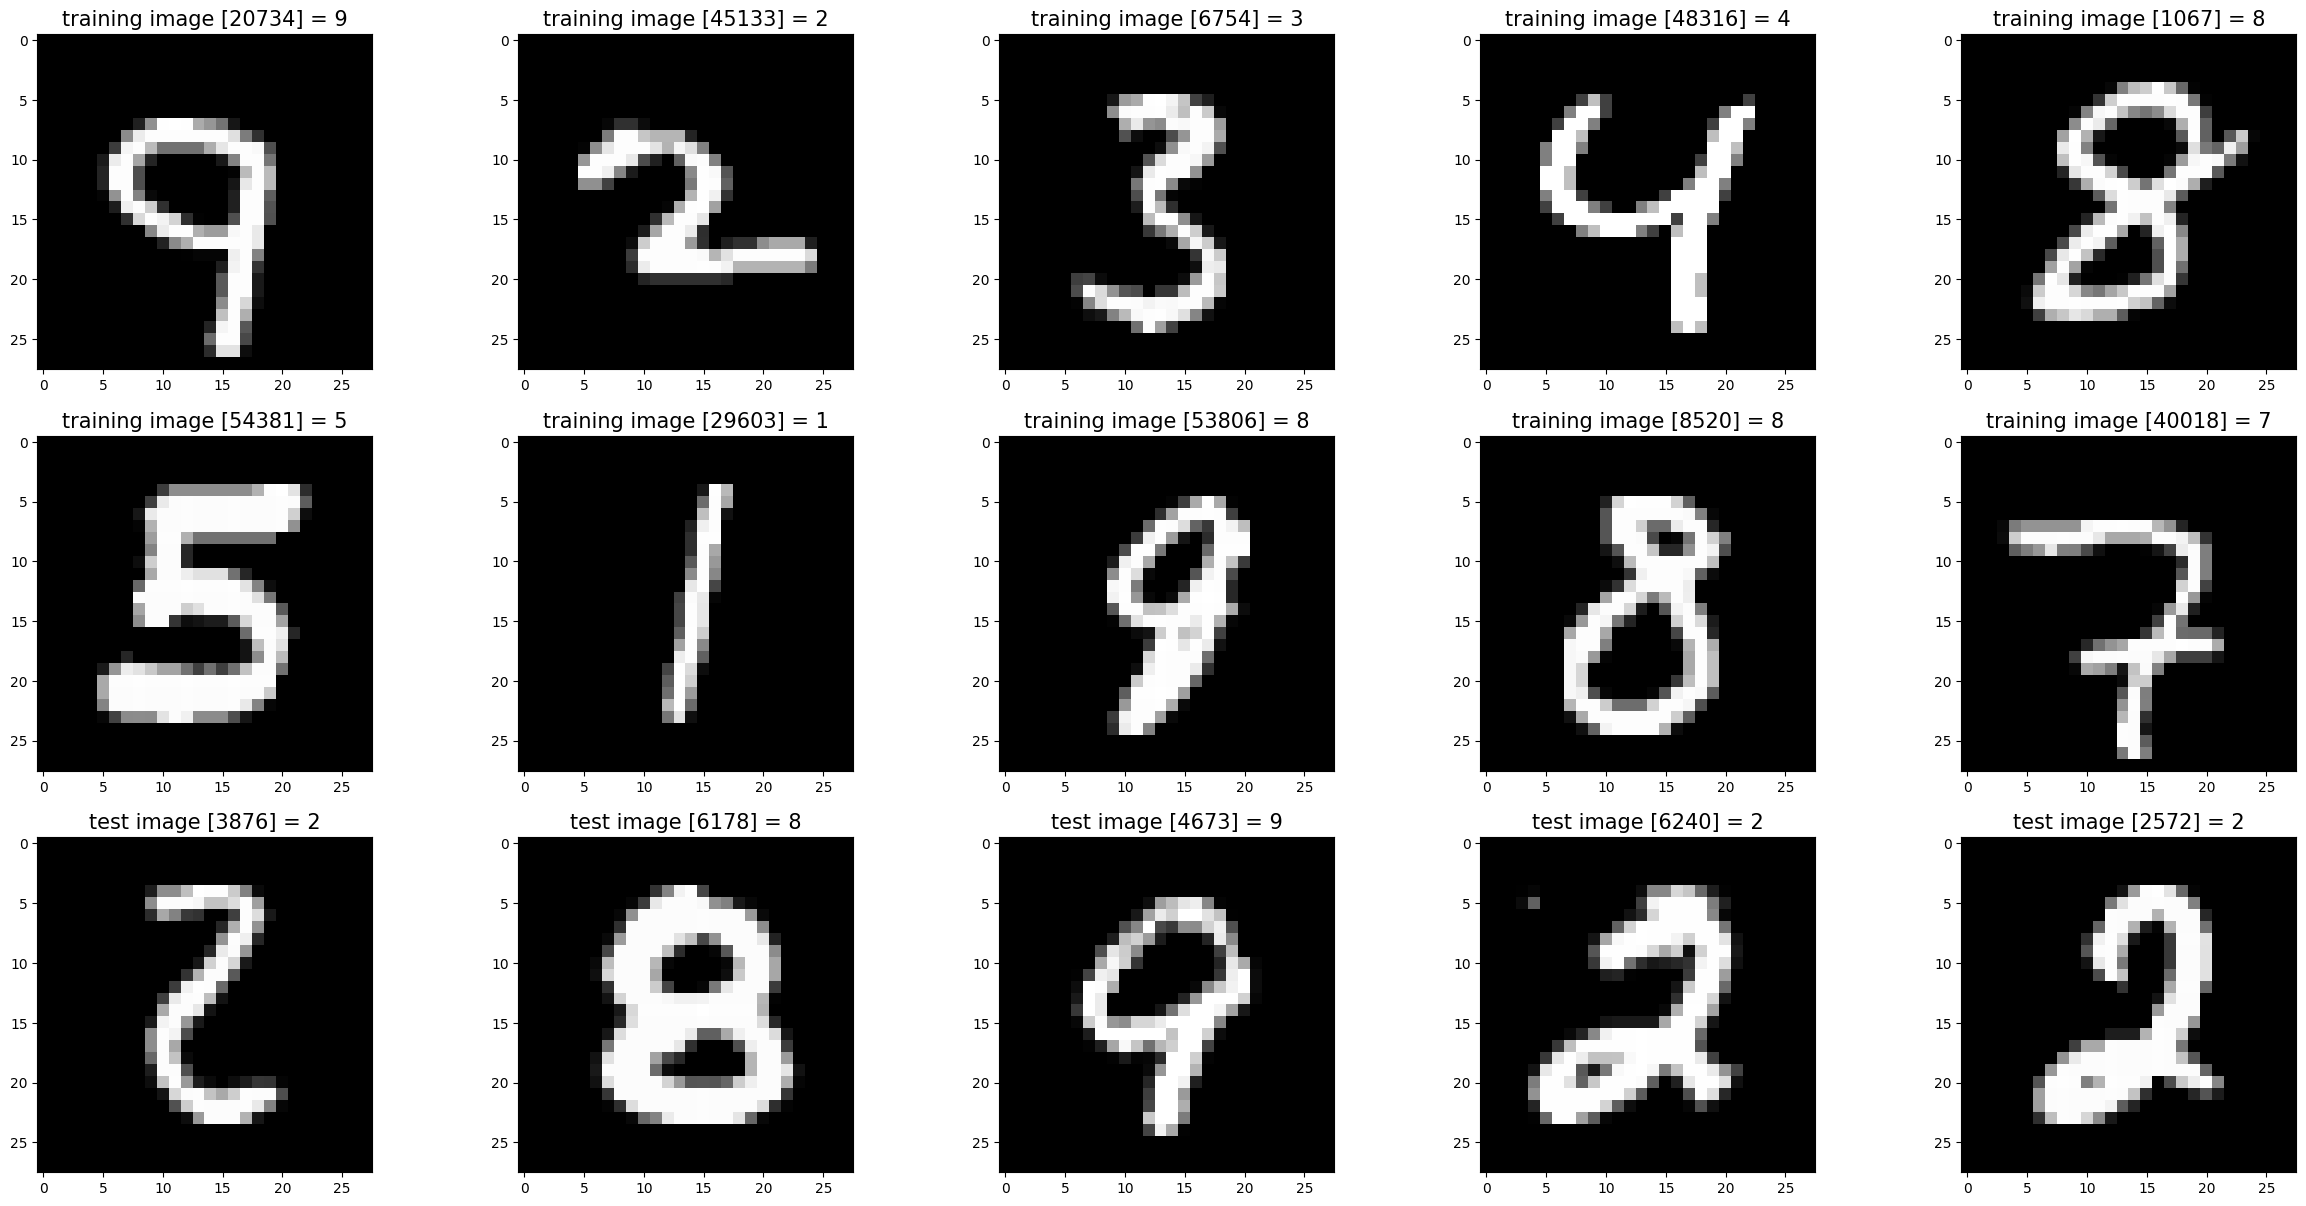

In [ ]:
def show_images(images, title_texts):
    cols = 5
    rows = int(len(images)/cols) + 1
    plt.figure(figsize=(30,20))
    index = 1
    for img, title_text in zip(images, title_texts):
        plt.subplot(rows, cols, index)
        plt.imshow(img, cmap=plt.cm.gray)
        if title_text != '':
            plt.title(title_text, fontsize=15)
        index += 1
    plt.show()

images_2_show = []
titles_2_show = []
for i in range(10):
    r = random.randint(0, len(X_train)-1)
    images_2_show.append(X_train[r])
    titles_2_show.append(f'training image [{r}] = {y_train[r]}')

for i in range(5):
    r = random.randint(0, len(X_test)-1)
    images_2_show.append(X_test[r])
    titles_2_show.append(f'test image [{r}] = {y_test[r]}')

show_images(images_2_show, titles_2_show)


## **1.2 Data Cleaning**

### **1.2.1 Check if all images are 28x28**

In [ ]:
print('The shape of the training inputs:', X_train.shape)
print('The shape of the training labels:',y_train.shape)
print('The shape of the testing inputs:',X_test.shape)
print('The shape of the testing labels:',y_test.shape)

The shape of the training inputs: (60000, 28, 28)
The shape of the training labels: (60000,)
The shape of the testing inputs: (10000, 28, 28)
The shape of the testing labels: (10000,)


### **1.2.2 Check for NaN values**

In [ ]:
print("NaN in training set:", np.isnan(X_train).sum())
print("NaN in testing set:", np.isnan(X_test).sum())

NaN in training set: 0
NaN in testing set: 0


### **1.2.3 Check pixel range**

In [ ]:
print("Pixel range in training set:", X_train.min(), X_train.max())
print("Pixel range in testing set:", X_test.min(), X_test.max())

Pixel range in training set: 0 255
Pixel range in testing set: 0 255


### **1.2.4 Normalize pixel values**

In [ ]:
X_train = X_train.reshape(len(X_train), -1).astype("float32") / 255.0
X_test  = X_test.reshape(len(X_test), -1).astype("float32") / 255.0

In [ ]:
print('The shape of the flatten training inputs:', X_train.shape)
print('The shape of the flatten testing inputs:',X_test.shape)
print("Pixel range in normalized training set:", X_train.min(), X_train.max())
print("Pixel range in normalized testing set:", X_test.min(), X_test.max())
print("Data type of updated training set:", X_train.dtype)
print("Data type of updated testing set:", X_test.dtype)

The shape of the flatten training inputs: (60000, 784)
The shape of the flatten testing inputs: (10000, 784)
Pixel range in normalized training set: 0.0 1.0
Pixel range in normalized testing set: 0.0 1.0
Data type of updated training set: float32
Data type of updated testing set: float32


### **1.2.5 Remove duplicates**

In [ ]:
#Training set
#Find duplicate images
_, unique_idx = np.unique(X_train, return_index=True, axis=0)

#Keep only unique images
X_train = X_train[unique_idx]
y_train = y_train[unique_idx]

#Testing set
#Find duplicate images
_, unique_idx = np.unique(X_test, return_index=True, axis=0)

#Keep only unique images
X_test = X_test[unique_idx]
y_test = y_test[unique_idx]

print("X_train after removing duplicates:", X_train.shape)
print("y_train after removing duplicates:", y_train.shape)
print("X_test after removing duplicates:", X_test.shape)
print("y_test after removing duplicates:", y_test.shape)

X_train after removing duplicates: (60000, 784)
y_train after removing duplicates: (60000,)
X_test after removing duplicates: (10000, 784)
y_test after removing duplicates: (10000,)


# **2.0 Data Training**

## **Predefined functions**

In [ ]:
def show_matrix(cm, class_names=None, title="Confusion Matrix"):
    plt.figure(figsize=(8,6))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
                xticklabels=class_names, yticklabels=class_names)
    plt.xlabel("Predicted")
    plt.ylabel("True")
    plt.title(title)
    plt.show()

In [ ]:
def plot_pr_curve(y_train, y_pred_cv, title):
  # Binarize labels for multiclass PR curve
  y_train_bin = label_binarize(y_train, classes=np.arange(10))
  y_pred_bin  = label_binarize(y_pred_cv, classes=np.arange(10))

  n_classes = y_train_bin.shape[1]

  plt.figure(figsize=(10, 8))

  # Compute PR curve for each class
  for i in range(n_classes):
      precision, recall, _ = precision_recall_curve(y_train_bin[:, i], y_pred_bin[:, i])
      avg_precision = average_precision_score(y_train_bin[:, i], y_pred_bin[:, i])
      plt.plot(recall, precision, lw=2, label=f"Digit {i} (AP={avg_precision:.2f})")

  plt.xlabel("Recall")
  plt.ylabel("Precision")
  plt.title(title)
  plt.legend()
  plt.grid(True)
  plt.show()

In [ ]:
def plot_roc_curve (model, title):
  # Binarize labels (MNIST has 10 classes: 0–9)
  y_test_bin = label_binarize(y_test, classes=np.arange(10))
  n_classes = y_test_bin.shape[1]

  # Get probability estimates (not predicted labels!)
  y_score = cross_val_predict(model, X_test, y_test, cv=5, method="predict_proba") # Use flattened data

  # Compute ROC curve and AUC for each class
  fpr = dict()
  tpr = dict()
  roc_auc = dict()

  for i in range(n_classes):
      fpr[i], tpr[i], _ = roc_curve(y_test_bin[:, i], y_score[:, i])
      roc_auc[i] = auc(fpr[i], tpr[i])

  # Plot ROC curves for all classes
  plt.figure(figsize=(10, 8))
  for i in range(n_classes):
      plt.plot(fpr[i], tpr[i], label=f"Digit {i} (AUC = {roc_auc[i]:.2f})")

  plt.plot([0, 1], [0, 1], "k--")  # Diagonal line
  plt.xlabel("False Positive Rate")
  plt.ylabel("True Positive Rate")
  plt.title(title)
  plt.legend(loc="lower right")
  plt.show()

In [ ]:
def plot_roc_microavg(model, X, y, title):
    # Binarize labels
    y_bin = label_binarize(y, classes=np.arange(10))
    n_classes = y_bin.shape[1]

    # Get probability estimates
    y_score = model.predict_proba(X)

    # Compute micro-average ROC curve and AUC
    fpr_micro, tpr_micro, _ = roc_curve(y_bin.ravel(), y_score.ravel())
    roc_auc_micro = auc(fpr_micro, tpr_micro)

    # Plot micro-average ROC curve
    plt.figure(figsize=(8, 6))
    plt.plot(fpr_micro, tpr_micro, label=f"Micro-average ROC (AUC = {roc_auc_micro:.2f})",
             color='deeppink', linewidth=4)

    plt.plot([0, 1], [0, 1], "k--")  # Diagonal line
    plt.xlabel("False Positive Rate")
    plt.ylabel("True Positive Rate")
    plt.title(title)
    plt.legend(loc="lower right")
    plt.show()

In [ ]:
def display_correct_classifications(y_test_pred, title):
  # Sample Predictions - Correct Classifications
  plt.subplot(4, 9, 19) # Place in the 3rd row, 1st column of a 4x9 grid
  plt.axis('off')  # Turn off the axis for this subplot
  # Find correctly classified samples
  correct_mask = y_test == y_test_pred
  correct_indices = np.where(correct_mask)[0][:9]

  for i, idx in enumerate(correct_indices):
      plt.subplot(4, 9, 19 + i)  # 3rd row, positions 1-9 in a 4x9 grid
      image = X_test[idx].reshape(28, 28)
      plt.imshow(image, cmap='gray')
      plt.title(f'True: {y_test[idx]}\nPred: {y_test_pred[idx]}',
                fontsize=10, color='green')
      plt.axis('off')

  plt.suptitle(title, fontsize=12, fontweight='bold', y=0.30) # Adjust y position

In [ ]:
def display_incorrect_classifications(y_test_pred, title):
  # Sample Predictions - Incorrect Classifications
  plt.subplot(4, 9, 28) # Place in the 4th row, 1st column of a 4x9 grid
  plt.axis('off')  # Turn off the axis for this subplot
  # Find incorrectly classified samples
  incorrect_mask = y_test != y_test_pred
  incorrect_indices = np.where(incorrect_mask)[0][:9]

  for i, idx in enumerate(incorrect_indices):
      plt.subplot(4, 9, 28 + i)  # 4th row, positions 1-9 in a 4x9 grid
      image = X_test[idx].reshape(28, 28)
      plt.imshow(image, cmap='gray')
      plt.title(f'True: {y_test[idx]}\nPred: {y_test_pred[idx]}',
                fontsize=10, color='red')
      plt.axis('off')

  plt.suptitle(title, fontsize=12, fontweight='bold', y=0.10) # Adjust y position

In [ ]:
def plot_training_test_accuracy(model, title):
  # Plottnig training accuracy vs test set accuracy
  ax = plt.subplot(3, 3, 7)

  # Make predictions on training and test sets
  y_train_pred = model.predict(X_train)
  y_test_pred = model.predict(X_test)

  # Calculate accuracies
  train_accuracy = accuracy_score(y_train, y_train_pred)
  test_accuracy = accuracy_score(y_test, y_test_pred)

  accuracies = [train_accuracy, test_accuracy]
  labels = ['Training', 'Test']
  colors = ['lightblue', 'lightcoral']

  bars = ax.bar(labels, accuracies, color=colors, alpha=0.7, edgecolor='navy')
  ax.set_title(title, fontsize=14, fontweight='bold', pad=18)  # add title padding
  ax.set_ylabel('Accuracy')

  # add headroom so value labels don't kiss the title
  ax.set_ylim(0, max(1.0, max(accuracies) + 0.08))

  # value labels with a bit more offset
  ax.bar_label(bars, labels=[f'{a:.4f}' for a in accuracies],
              padding=8, fontweight='bold')

  ax.grid(axis='y', alpha=0.3)

  # push the whole grid slightly lower in the figure (more space at the top)
  ax.figure.subplots_adjust(top=0.86)

In [ ]:
def plot_error_rate_by_digit(y_test_pred, title):
  # Plotting error rate by each digit
  fig, ax = plt.subplots(figsize=(9, 5), dpi=80, constrained_layout=True)

  classes  = np.arange(10)
  counts   = np.array([(y_test == d).sum() for d in classes])
  mistakes = np.array([((y_test == d) & (y_test_pred != d)).sum() for d in classes])
  errs = np.divide(mistakes, counts, out=np.zeros_like(mistakes, dtype=float), where=counts>0)

  order = np.argsort(errs)[::-1]
  cls, errs = classes[order], errs[order]

  bars = ax.barh(cls, errs, height=0.6, alpha=0.85, color='darkred')

  ax.set_title(title, fontsize=18, fontweight='bold')
  ax.set_xlabel('Error Rate', fontsize=14)
  ax.set_ylabel('Digit Class', fontsize=14)
  ax.set_yticks(cls); ax.set_yticklabels(cls, fontsize=12)
  ax.tick_params(axis='x', labelsize=12)
  ax.xaxis.set_major_formatter(PercentFormatter(1.0))

  ax.set_xlim(0, min(1.0, errs.max() + 0.15))  # room for labels

  for bar, val in zip(bars, errs):
      ax.text(bar.get_width() + 0.02, bar.get_y() + bar.get_height()/2,
              f'{val:.1%}', va='center', ha='left', fontsize=14, fontweight='bold',
              bbox=dict(boxstyle='round,pad=0.2', fc='white', ec='none', alpha=0.9),
              clip_on=False)

  ax.grid(axis='x', alpha=0.3, linestyle='--')
  ax.invert_yaxis()

In [ ]:
def plot_most_confused_digit_pair(cm, title):
  # Most Confused Digit Pair
  fig, ax = plt.subplots(figsize=(8, 5), dpi=80, constrained_layout=True)

  # zero-out the diagonal then pick the top 10 off-diagonal confusions
  cm_no_diag = cm.copy()
  np.fill_diagonal(cm_no_diag, 0)
  i_idx, j_idx = np.where(cm_no_diag > 0)
  counts = cm_no_diag[i_idx, j_idx]

  order = np.argsort(counts)[::-1]
  i_idx, j_idx, counts = i_idx[order], j_idx[order], counts[order]
  top_k = min(10, len(counts))

  labels = [f"{i}→{j}" for i, j in zip(i_idx[:top_k], j_idx[:top_k])]
  vals   = counts[:top_k]

  bars = ax.barh(np.arange(top_k), vals, color='orange')
  ax.set_title(title, fontsize=18, fontweight='bold')
  ax.set_xlabel('Number of Misclassifications', fontsize=14)
  ax.set_ylabel('Digit Pair', fontsize=14)
  ax.set_yticks(np.arange(top_k))
  ax.set_yticklabels(labels, fontsize=12)
  ax.tick_params(axis='x', labelsize=12)
  ax.invert_yaxis()

  # value labels to the right of each bar (big + readable)
  for y, v in enumerate(vals):
      ax.annotate(f'{int(v)}',
                  xy=(v, y), xytext=(6, 0), textcoords='offset points',
                  va='center', ha='left', fontsize=12, fontweight='bold',
                  bbox=dict(boxstyle='round,pad=0.2', fc='white', ec='none', alpha=0.9),
                  clip_on=False)

  ax.grid(axis='x', alpha=0.3, linestyle='--')

In [ ]:
def plot_cv_scores(title, cv_scores):
  # Plot CV scores
  plt.figure(figsize=(10, 6))
  plt.subplot(1, 2, 1)
  plt.plot(range(1, 6), cv_scores, 'bo-', linewidth=2, markersize=8)
  plt.title(title, fontsize=14, fontweight='bold')
  plt.xlabel('Fold')
  plt.ylabel('Accuracy')
  plt.grid(True, alpha=0.3)
  plt.ylim(cv_scores.min() - 0.01, cv_scores.max() + 0.01)

In [ ]:
def plot_learning_curve(estimator, X, y, title, cv=None, n_jobs=None, train_sizes=np.linspace(.1, 1.0, 5)):
    """
    Generate a simple plot of the validation learning curve.

    Parameters
    ----------
    estimator : object type that implements the "fit" and "predict" methods
        An object of that type which is cloned for each validation.

    X : array-like of shape (n_samples, n_features)
        Training vectors, where n_samples is the number of samples and
        n_features is the number of features.

    y : array-like of shape (n_samples) or (n_samples, n_features)
        Target relative to X for classification or regression;
        None for unsupervised learning.

    title : string
        Title for the chart.

    cv : int, cross-validation generator or an iterable, default=None
        Determines the cross-validation splitting strategy.
        Possible inputs for cv are:
          - None, to use the default 5-fold cross-validation,
          - integer, to specify the number of folds.
          - :term:`CV splitter`,
          - An iterable yielding (train, test) splits as arrays of indices.

        For integer/None inputs, if y is binary or multiclass,
        :class:`StratifiedKFold` is used. In all other cases, :class:`KFold`
        is used. These splitters are instantiated with `shuffle=False` and
        the default `random_state` unless `shuffle=True` and/state is given.

    n_jobs : int or None, default=None
        Number of jobs to run in parallel.
        ``-1`` means using all processors. See :term:`Glossary <n_jobs>`.

    train_sizes : array-like of shape (n_ticks,), default=np.linspace(0.1, 1.0, 5)
        Relative or absolute numbers of training examples that will be used to
        generate the learning curve. If the dtype is float, it is considered as a
        fraction of the maximum number of samples (that is, the number of samples
        in the training set times the largest fraction), unless it is an integer,
        in which case it is treated as absolute numbers of training examples.
        Note that for classification problems and stratified cross-validation,
        the last fraction may be slightly smaller than 1.0 because of stratification.

    """
    plt.figure()
    plt.title(title)
    plt.xlabel("Training examples")
    plt.ylabel("Score")

    train_sizes, train_scores, test_scores = learning_curve(
        estimator, X, y, cv=cv, n_jobs=n_jobs, train_sizes=train_sizes)

    train_scores_mean = np.mean(train_scores, axis=1)
    train_scores_std = np.std(train_scores, axis=1)
    test_scores_mean = np.mean(test_scores, axis=1)
    test_scores_std = np.std(test_scores, axis=1)

    plt.grid()

    plt.fill_between(train_sizes, train_scores_mean - train_scores_std,
                     train_scores_mean + train_scores_std, alpha=0.1,
                     color="r")
    plt.fill_between(train_sizes, test_scores_mean - test_scores_std,
                     test_scores_mean + test_scores_std, alpha=0.1, color="g")
    plt.plot(train_sizes, train_scores_mean, 'o-', color="r",
             label="Training score")
    plt.plot(train_sizes, test_scores_mean, 'o-', color="g",
             label="Cross-validation score")

    plt.legend(loc="best")
    return plt

In [ ]:
def plot_roc_curve_decision(model, X_test, y_test, title="ROC Curve"):
    # Get decision scores
    y_score = model.decision_function(X_test)

    # Binarize labels for multiclass
    classes = np.unique(y_test)
    y_test_bin = label_binarize(y_test, classes=classes)

    plt.figure(figsize=(8, 6))

    for i, cls in enumerate(classes):
        fpr, tpr, _ = roc_curve(y_test_bin[:, i], y_score[:, i])
        roc_auc = auc(fpr, tpr)
        plt.plot(fpr, tpr, lw=2, label=f"Class {cls} (AUC = {roc_auc:.2f})")

    # Random baseline
    plt.plot([0, 1], [0, 1], linestyle="--", color="gray")

    plt.title(title)
    plt.xlabel("False Positive Rate")
    plt.ylabel("True Positive Rate")
    plt.legend(loc="lower right")
    plt.show()


In [ ]:


def plot_roc_microavg_decision(model, X_test, y_test, title="Micro-average ROC (OvR)"):
    # Get decision scores
    y_score = model.decision_function(X_test)

    # Binarize labels
    classes = np.unique(y_test)
    y_test_bin = label_binarize(y_test, classes=classes)

    # Compute micro-average ROC curve
    fpr, tpr, _ = roc_curve(y_test_bin.ravel(), y_score.ravel())
    roc_auc = auc(fpr, tpr)

    plt.figure(figsize=(8, 6))
    plt.plot(fpr, tpr, color="blue", lw=2, label=f"Micro-average ROC (AUC = {roc_auc:.2f})")

    # Random baseline
    plt.plot([0, 1], [0, 1], linestyle="--", color="gray")

    plt.title(title)
    plt.xlabel("False Positive Rate")
    plt.ylabel("True Positive Rate")
    plt.legend(loc="lower right")
    plt.show()


## **2.1 K-Nearest Neighbors**

### **2.1.1 Training model**

In [ ]:
knn = KNeighborsClassifier()

# Train the model
print("Training in progress... This may take a few minutes.")
knn.fit(X_train, y_train)
print("✓ Model training completed!")

Training in progress... This may take a few minutes.
✓ Model training completed!


In [ ]:
# Make predictions on training and test sets
y_train_pred_knn = knn.predict(X_train)
y_test_pred_knn = knn.predict(X_test)

# Calculate accuracies
train_accuracy = accuracy_score(y_train, y_train_pred_knn)
test_accuracy = accuracy_score(y_test, y_test_pred_knn)

print(f"Training Accuracy: {train_accuracy:.4f} ({train_accuracy*100:.2f}%)")
print(f"Test Accuracy: {test_accuracy:.4f} ({test_accuracy*100:.2f}%)")
print(f"Overfitting Check: {abs(train_accuracy - test_accuracy):.4f}")

Training Accuracy: 0.9819 (98.19%)
Test Accuracy: 0.9688 (96.88%)
Overfitting Check: 0.0131


### **2.1.2 Fine-tune the model using Grid Search**

In [ ]:
# define param_grid (you may used the one defined above)
param_grid = {
    'n_neighbors': [3, 4, 5],
    'weights': ['uniform', 'distance']
}
# create an instance of GridSearchCV using param_grid with 5-fold cv
grid_search = GridSearchCV(
    estimator=knn,
    param_grid=param_grid,
    scoring='accuracy',
    cv=5,
    n_jobs=-1
)

print ('Performing grid search...', end = '')
# perform grid search
grid_search.fit(X_train, y_train)

print("Best params:", grid_search.best_params_)
print(f"Best CV accuracy: {grid_search.best_score_:.4f}")

Performing grid search...Best params: {'n_neighbors': 4, 'weights': 'distance'}
Best CV accuracy: 0.9385


### **2.1.3 Performance measure: Precision, Recall and F1 Score**

In [ ]:
best_model_knn = grid_search.best_estimator_
y_test_pred_knn = best_model_knn.predict(X_test)

print("Test metrics:")
print("  Acc:", accuracy_score(y_test, y_test_pred_knn))
print("  Prec(macro):", precision_score(y_test, y_test_pred_knn, average="macro", zero_division=0))
print("  Rec(macro):",  recall_score(y_test, y_test_pred_knn, average="macro", zero_division=0))
print("  F1(macro):",   f1_score(y_test, y_test_pred_knn, average="macro", zero_division=0))
print("\nClassification report:\n", classification_report(y_test, y_test_pred_knn, digits=4, zero_division=0))

Test metrics:
  Acc: 0.9714
  Prec(macro): 0.9715597201945959
  Rec(macro): 0.9710823052664403
  F1(macro): 0.971224084176584

Classification report:
               precision    recall  f1-score   support

           0     0.9730    0.9929    0.9828       980
           1     0.9683    0.9974    0.9826      1135
           2     0.9842    0.9641    0.9741      1032
           3     0.9682    0.9644    0.9663      1010
           4     0.9754    0.9674    0.9714       982
           5     0.9631    0.9664    0.9647       892
           6     0.9783    0.9875    0.9829       958
           7     0.9595    0.9669    0.9632      1028
           8     0.9882    0.9446    0.9659       974
           9     0.9575    0.9594    0.9584      1009

    accuracy                         0.9714     10000
   macro avg     0.9716    0.9711    0.9712     10000
weighted avg     0.9715    0.9714    0.9714     10000



In [ ]:
# Precision, Recall, F1-Score for each class
precision, recall, f1, support = precision_recall_fscore_support(y_test, y_test_pred_knn)

# Create a summary DataFrame
metrics_df_knn = pd.DataFrame({
    'Digit': range(10),
    'Precision': precision,
    'Recall': recall,
    'F1-Score': f1,
    'Support': support
})

print("\nPer-Class Metrics:")
print(metrics_df_knn.round(4))


Per-Class Metrics:
   Digit  Precision  Recall  F1-Score  Support
0      0     0.9730  0.9929    0.9828      980
1      1     0.9683  0.9974    0.9826     1135
2      2     0.9842  0.9641    0.9741     1032
3      3     0.9682  0.9644    0.9663     1010
4      4     0.9754  0.9674    0.9714      982
5      5     0.9631  0.9664    0.9647      892
6      6     0.9783  0.9875    0.9829      958
7      7     0.9595  0.9669    0.9632     1028
8      8     0.9882  0.9446    0.9659      974
9      9     0.9575  0.9594    0.9584     1009


In [ ]:
# Make predictions on training and test sets
y_train_pred_knn = best_model_knn.predict(X_train)

# Calculate accuracies
train_accuracy_knn = accuracy_score(y_train, y_train_pred_knn)
test_accuracy_knn = accuracy_score(y_test, y_test_pred_knn)

print(f"Training Accuracy: {train_accuracy_knn:.4f} ({train_accuracy_knn*100:.2f}%)")
print(f"Test Accuracy: {test_accuracy_knn:.4f} ({test_accuracy_knn*100:.2f}%)")
print(f"Overfitting Check: {abs(train_accuracy_knn - test_accuracy_knn):.4f}")

Training Accuracy: 1.0000 (100.00%)
Test Accuracy: 0.9714 (97.14%)
Overfitting Check: 0.0286


### **2.1.4 Performance measure: Confusion Matrix**

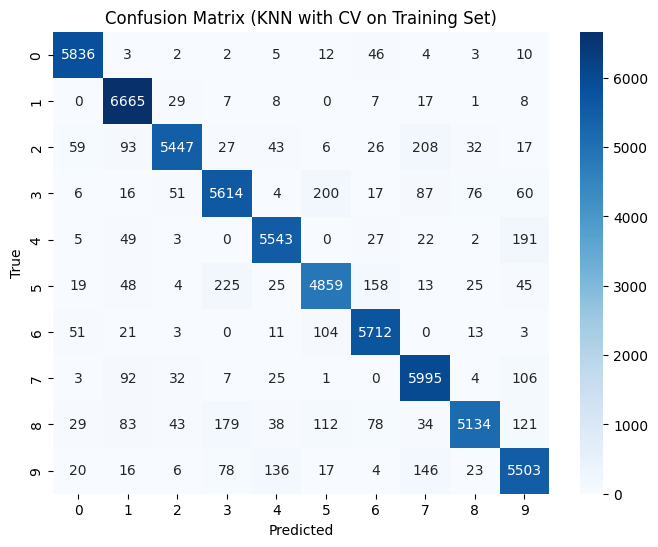

In [ ]:
# Cross-val predict of training data using KNN
y_pred_cv_knn_train = cross_val_predict(best_model_knn, X_train, y_train, cv=5)

# Compute confusion matrix
cm_knn_train_cv = confusion_matrix(y_train, y_pred_cv_knn_train)
show_matrix(cm_knn_train_cv, class_names=[str(i) for i in range(10)],
            title="Confusion Matrix (KNN with CV on Training Set)")

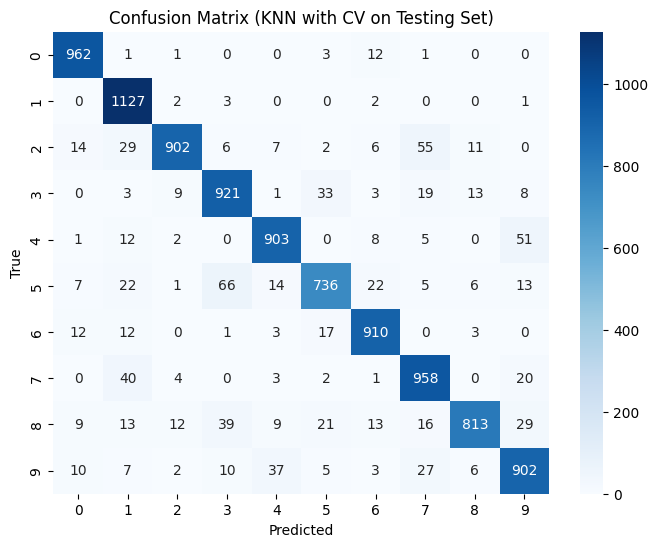

In [ ]:
# Cross-val predict of testing data using KNN
y_pred_cv_knn_test = cross_val_predict(best_model_knn, X_test, y_test, cv=5)

# Compute confusion matrix
cm_knn_test_cv = confusion_matrix(y_test, y_pred_cv_knn_test)
show_matrix(cm_knn_test_cv, class_names=[str(i) for i in range(10)],
            title="Confusion Matrix (KNN with CV on Testing Set)")

### **2.1.5 Performance Measure: Precision-Recall curve**

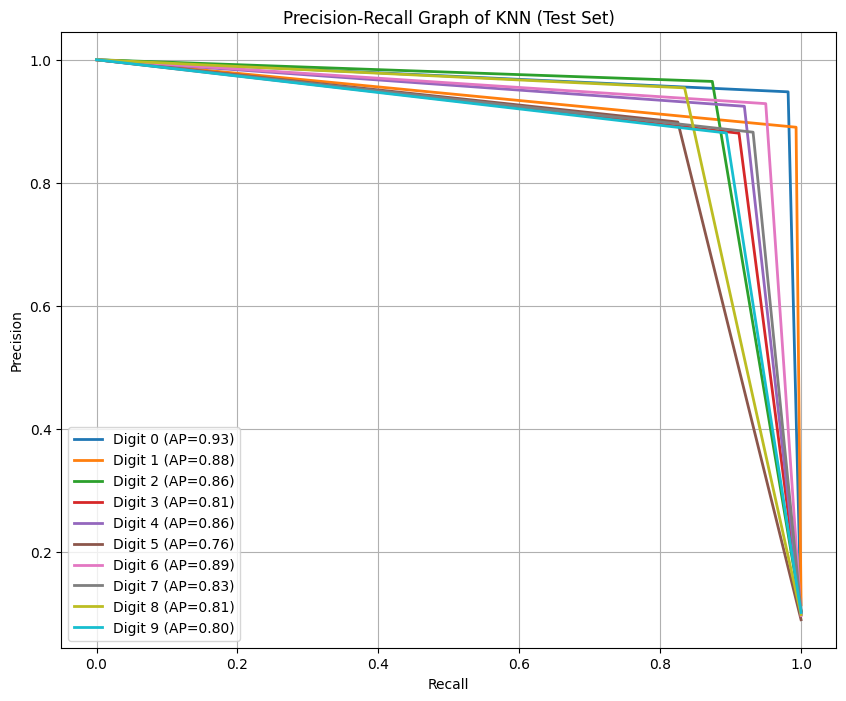

In [ ]:
plot_pr_curve(y_test, y_pred_cv_knn_test, "Precision-Recall Graph of KNN (Test Set)")

### **2.1.6 Performance measure: ROC curve**

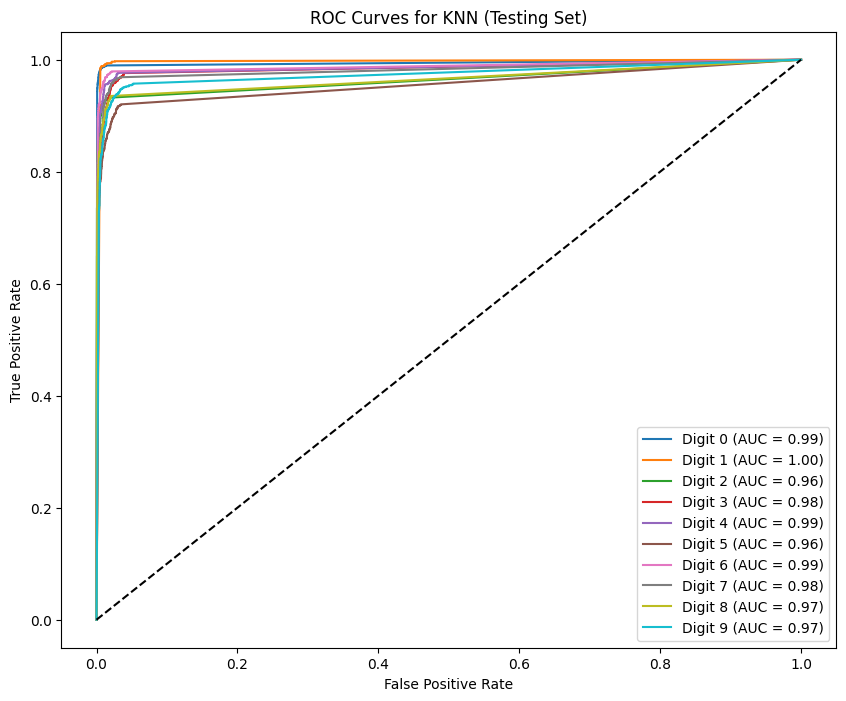

In [ ]:
plot_roc_curve(best_model_knn, 'ROC Curves for KNN (Testing Set)')

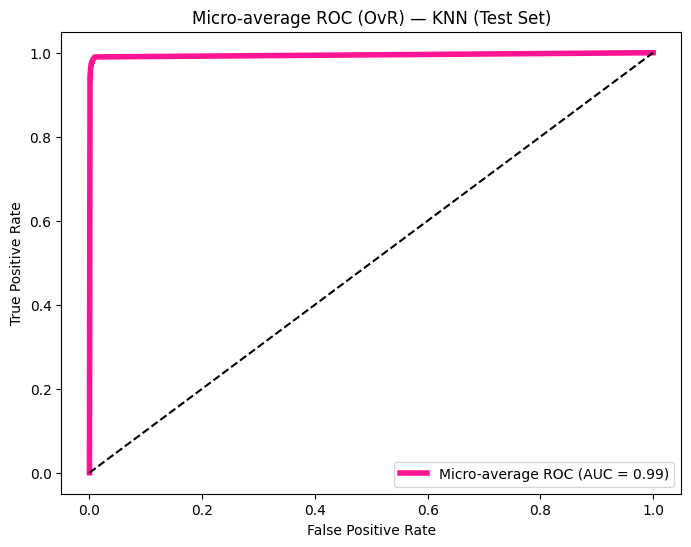

In [ ]:
# Plot Micro-average ROC for Logistic Regression on Test Set
plot_roc_microavg(best_model_knn, X_test, y_test,
                  title="Micro-average ROC (OvR) — KNN (Test Set)")

### **2.1.7 Performance measure: Visualizing Correct and Incorrect Classification**

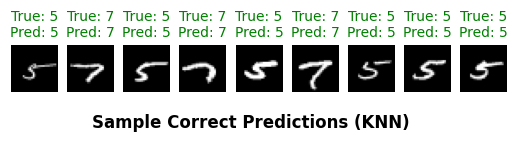

In [ ]:
display_correct_classifications(y_test_pred_knn, 'Sample Correct Predictions (KNN)')

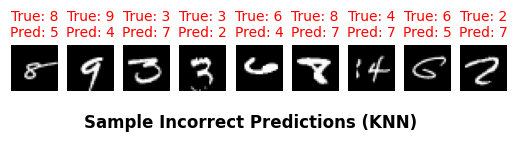

In [ ]:
display_incorrect_classifications(y_test_pred_knn, 'Sample Incorrect Predictions (KNN)')

### **2.1.8 Performance measure: Visualizing multiple chart for more insights**

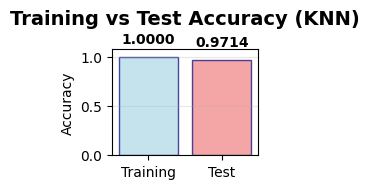

In [ ]:
plot_training_test_accuracy(best_model_knn, 'Training vs Test Accuracy (KNN)')

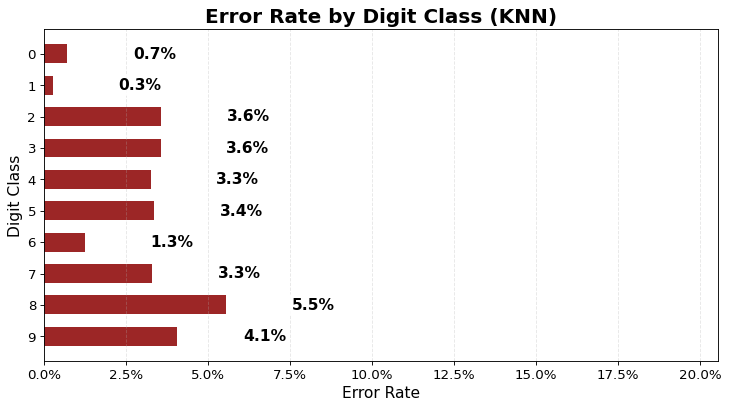

In [ ]:
plot_error_rate_by_digit(y_test_pred_knn, 'Error Rate by Digit Class (KNN)')

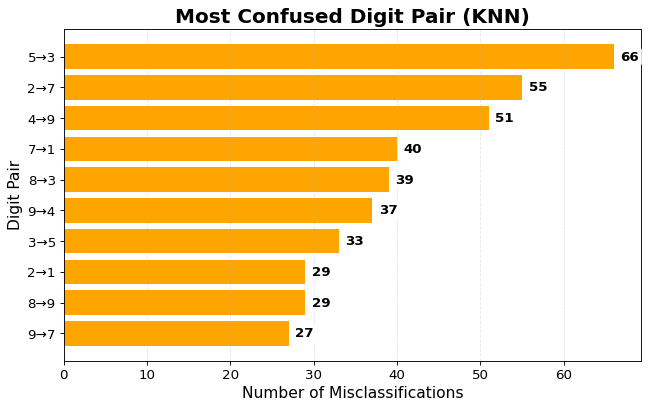

In [ ]:
plot_most_confused_digit_pair(cm_knn_test_cv, 'Most Confused Digit Pair (KNN)')

In [ ]:
# Perform 5-fold cross-validation
cv_scores_knn = cross_val_score(best_model_knn, X_test, y_test, cv=5, scoring='accuracy', n_jobs=-1)

print(f"Cross-Validation Scores: {cv_scores_knn}")
print(f"Mean CV Accuracy: {cv_scores_knn.mean():.4f} ")

Cross-Validation Scores: [0.8405 0.955  0.957  0.943  0.8715]
Mean CV Accuracy: 0.9134 


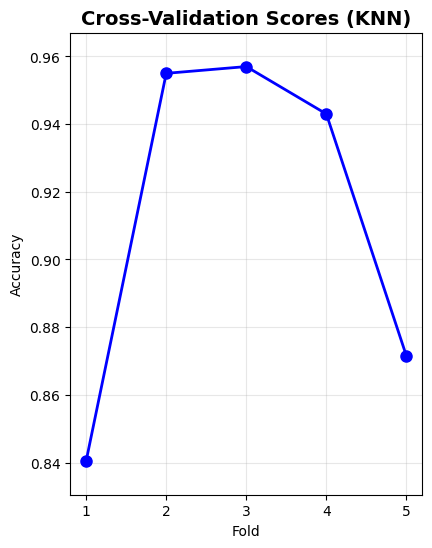

In [ ]:
plot_cv_scores("Cross-Validation Scores (KNN)", cv_scores_knn)

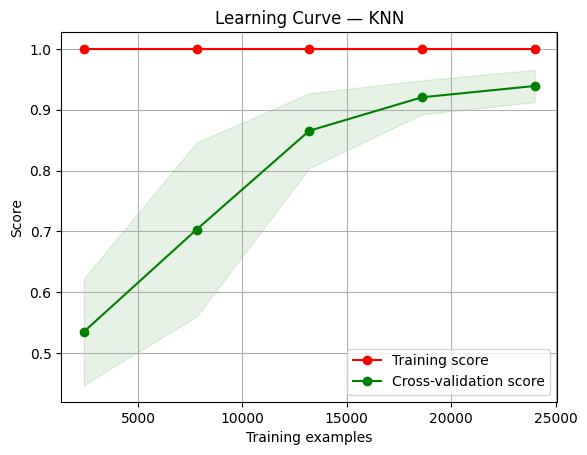

In [ ]:
# Plot Learning Curve for KNN
plot_learning_curve(best_model_knn, X_train[:30000], y_train[:30000],
                    title="Learning Curve — KNN", cv=5, n_jobs=-1)
plt.show() # Added plt.show() to display the plot

In [ ]:
print("\n" + "="*60)
print("K-NEAREST NEIGHBORS MODEL SUMMARY")
print("="*60)

print(f"Dataset: MNIST Handwritten Digits")
print(f"Training Samples: {len(X_train)}")
print(f"Test Samples: {len(X_test)}")
print(f"Number of Features: {X_train.shape[1]}")
print(f"Number of Classes: 10")
print()
print(f"Model Performance:")
print(f"  • Training Accuracy: {train_accuracy_knn:.4f} ({train_accuracy_knn*100:.2f}%)")
print(f"  • Test Accuracy: {test_accuracy_knn:.4f} ({test_accuracy_knn*100:.2f}%)")
print(f"  • Cross-Validation Score: {cv_scores_knn.mean():.4f} (±{cv_scores_knn.std()*2:.4f})")
print()
print(f"Model Characteristics:")
print(f"  • N_neighbors: 4")
print(f"  • Weights: Distance")


K-NEAREST NEIGHBORS MODEL SUMMARY
Dataset: MNIST Handwritten Digits
Training Samples: 60000
Test Samples: 10000
Number of Features: 784
Number of Classes: 10

Model Performance:
  • Training Accuracy: 1.0000 (100.00%)
  • Test Accuracy: 0.9714 (97.14%)
  • Cross-Validation Score: 0.9134 (±0.0962)

Model Characteristics:
  • N_neighbors: 4
  • Weights: Distance


In [ ]:
# Find best and worst performing digits using F1-Score from metrics_df
if 'metrics_df_knn' in globals():
    # Find the index of the best and worst F1-scores
    best_digit_idx = metrics_df_knn['F1-Score'].argmax()
    worst_digit_idx = metrics_df_knn['F1-Score'].argmin()

    # Get the digit label and the corresponding F1-score
    best_digit = metrics_df_knn['Digit'][best_digit_idx]
    best_f1 = metrics_df_knn['F1-Score'][best_digit_idx]

    worst_digit = metrics_df_knn['Digit'][worst_digit_idx]
    worst_f1 = metrics_df_knn['F1-Score'][worst_digit_idx]

    print(f"  • Best Recognized Digit (based on F1-Score): {best_digit} ({best_f1:.4f} F1-score)")
    print(f"  • Most Challenging Digit (based on F1-Score): {worst_digit} ({worst_f1:.4f} F1-score)")
else:
    print("Error: metrics_df DataFrame not found. Please run the cell that generates metrics_df first.")

  • Best Recognized Digit (based on F1-Score): 6 (0.9829 F1-score)
  • Most Challenging Digit (based on F1-Score): 9 (0.9584 F1-score)


## **2.2 Logistic Regression**

### **2.2.1 Training model**

In [ ]:
# Initialize Logistic Regression model
# Using lbfgs solver for multiclass problems with increased max_iter
lr_model = LogisticRegression(
    max_iter=1000,
    solver='lbfgs',
    multi_class='ovr',  # One-vs-Rest for multiclass
    random_state=42,
    n_jobs=-1  # Use all available processors
)

# Train the model
print("Training in progress... This may take a few minutes.")
lr_model.fit(X_train, y_train)
print("✓ Model training completed!")

Training in progress... This may take a few minutes.
✓ Model training completed!


In [ ]:
# Make predictions on training and test sets
y_train_pred_lr = lr_model.predict(X_train)
y_test_pred_lr = lr_model.predict(X_test)

# Calculate accuracies
train_accuracy = accuracy_score(y_train, y_train_pred_lr)
test_accuracy = accuracy_score(y_test, y_test_pred_lr)

print(f"Training Accuracy: {train_accuracy:.4f} ({train_accuracy*100:.2f}%)")
print(f"Test Accuracy: {test_accuracy:.4f} ({test_accuracy*100:.2f}%)")
print(f"Overfitting Check: {abs(train_accuracy - test_accuracy):.4f}")

Training Accuracy: 0.9270 (92.70%)
Test Accuracy: 0.9209 (92.09%)
Overfitting Check: 0.0061


### **2.2.2 Fine-tune the model using Grid Search**

In [ ]:
# PCA(whiten) + GridSearchCV (cv=3)
import os, numpy as np, matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler, FunctionTransformer
from sklearn.decomposition import PCA
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

os.makedirs("outputs", exist_ok=True)

# Flatten images if they are (n, h, w) → (n, h*w)
flatten = FunctionTransformer(lambda X: X.reshape(X.shape[0], -1), validate=False)

# Pipeline: Flatten → Scale → PCA(whiten) → Multinomial LR
pipe_pca = Pipeline([
    ("flatten", flatten),
    ("scaler", StandardScaler(with_mean=False)),
    ("pca", PCA(n_components=0.95, whiten=True, random_state=42)),
    ("clf", LogisticRegression(multi_class="multinomial", solver="lbfgs"))
])

# Modest grid (principled): search only C (regularization strength)
cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)
param_grid = [{
    "clf__C": [0.5, 1.0, 1.5],
    "clf__max_iter": [300],
    "clf__tol": [1e-3],
}]

gs_pca = GridSearchCV(
    estimator=pipe_pca,
    param_grid=param_grid,
    scoring="accuracy",
    cv=cv,
    refit=True,
    n_jobs=-1,
    verbose=1
)
gs_pca.fit(X_train, y_train)

print("Best params:", gs_pca.best_params_)
print(f"Best CV accuracy: {gs_pca.best_score_:.4f}")


Fitting 3 folds for each of 3 candidates, totalling 9 fits
Best params: {'clf__C': 1.0, 'clf__max_iter': 300, 'clf__tol': 0.001}
Best CV accuracy: 0.9188


### **2.2.3 Performance measure: Precision, Recall and F1 Score**

In [ ]:
best_model_lr = gs_pca.best_estimator_
y_test_pred_lr = best_model_lr.predict(X_test)

print("Test metrics:")
print("  Acc:", accuracy_score(y_test, y_test_pred_lr))
print("  Prec(macro):", precision_score(y_test, y_test_pred_lr, average="macro", zero_division=0))
print("  Rec(macro):",  recall_score(y_test, y_test_pred_lr, average="macro", zero_division=0))
print("  F1(macro):",   f1_score(y_test, y_test_pred_lr, average="macro", zero_division=0))
print("\nClassification report:\n", classification_report(y_test, y_test_pred_lr, digits=4, zero_division=0))

Test metrics:
  Acc: 0.9259
  Prec(macro): 0.925116188268696
  Rec(macro): 0.9248858760600827
  F1(macro): 0.9249194831969871

Classification report:
               precision    recall  f1-score   support

           0     0.9560    0.9765    0.9662       980
           1     0.9619    0.9789    0.9703      1135
           2     0.9308    0.8992    0.9147      1032
           3     0.9086    0.9158    0.9122      1010
           4     0.9328    0.9328    0.9328       982
           5     0.9037    0.8733    0.8883       892
           6     0.9440    0.9509    0.9475       958
           7     0.9210    0.9183    0.9196      1028
           8     0.8789    0.8943    0.8865       974
           9     0.9133    0.9088    0.9111      1009

    accuracy                         0.9259     10000
   macro avg     0.9251    0.9249    0.9249     10000
weighted avg     0.9258    0.9259    0.9258     10000



In [ ]:
# Precision, Recall, F1-Score for each class
precision, recall, f1, support = precision_recall_fscore_support(y_test, y_test_pred_lr)

# Create a summary DataFrame
metrics_df_lr = pd.DataFrame({
    'Digit': range(10),
    'Precision': precision,
    'Recall': recall,
    'F1-Score': f1,
    'Support': support
})

print("\nPer-Class Metrics:")
print(metrics_df_lr.round(4))


Per-Class Metrics:
   Digit  Precision  Recall  F1-Score  Support
0      0     0.9560  0.9765    0.9662      980
1      1     0.9619  0.9789    0.9703     1135
2      2     0.9308  0.8992    0.9147     1032
3      3     0.9086  0.9158    0.9122     1010
4      4     0.9328  0.9328    0.9328      982
5      5     0.9037  0.8733    0.8883      892
6      6     0.9440  0.9509    0.9475      958
7      7     0.9210  0.9183    0.9196     1028
8      8     0.8789  0.8943    0.8865      974
9      9     0.9133  0.9088    0.9111     1009


In [ ]:
# Make predictions on training
y_train_pred_lr = best_model_lr.predict(X_train)

# Calculate accuracies
train_accuracy_lr = accuracy_score(y_train, y_train_pred_lr)
test_accuracy_lr = accuracy_score(y_test, y_test_pred_lr)

print(f"Training Accuracy: {train_accuracy_lr:.4f} ({train_accuracy_lr*100:.2f}%)")
print(f"Test Accuracy: {test_accuracy_lr:.4f} ({test_accuracy_lr*100:.2f}%)")
print(f"Overfitting Check: {abs(train_accuracy_lr - test_accuracy_lr):.4f}")

Training Accuracy: 0.9327 (93.27%)
Test Accuracy: 0.9259 (92.59%)
Overfitting Check: 0.0069


### **2.2.4 Performance measure: Confusion Matrix**

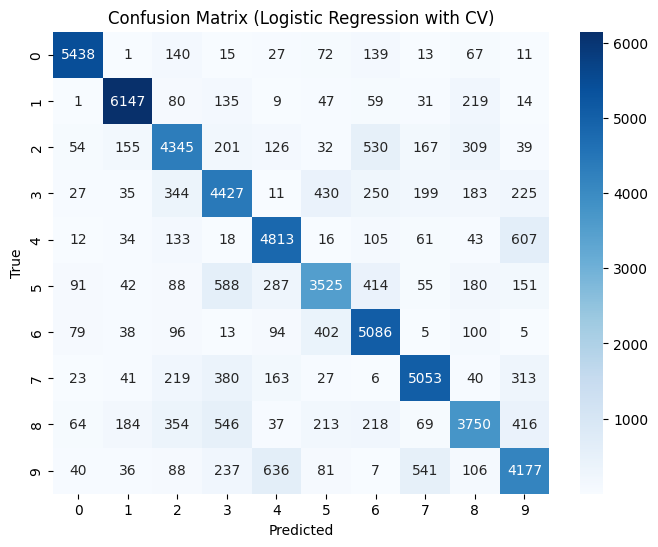

In [ ]:
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import confusion_matrix

# Cross-val predict using Logistic Regression model and flattened data
y_pred_cv_lr_train = cross_val_predict(lr_model, X_train, y_train, cv=5)

# Compute confusion matrix
cm_lr_cv = confusion_matrix(y_train, y_pred_cv_lr_train)
show_matrix(cm_lr_cv, class_names=[str(i) for i in range(10)],
            title="Confusion Matrix (Logistic Regression with CV)")

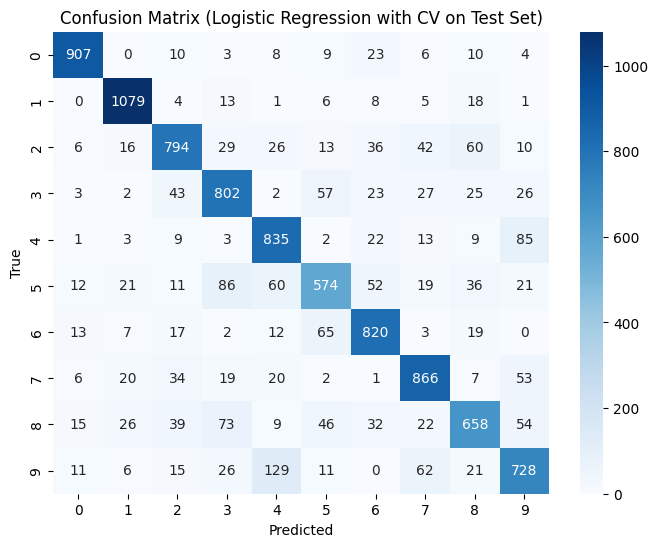

In [ ]:
# Cross-val predict using Logistic Regression model and flattened test data
y_pred_cv_lr_test = cross_val_predict(lr_model, X_test, y_test, cv=5)

# Compute confusion matrix
cm_lr_test_cv = confusion_matrix(y_test, y_pred_cv_lr_test)
show_matrix(cm_lr_test_cv, class_names=[str(i) for i in range(10)],
            title="Confusion Matrix (Logistic Regression with CV on Test Set)")

### **2.2.5 Performance Measure: Precision-Recall curve**

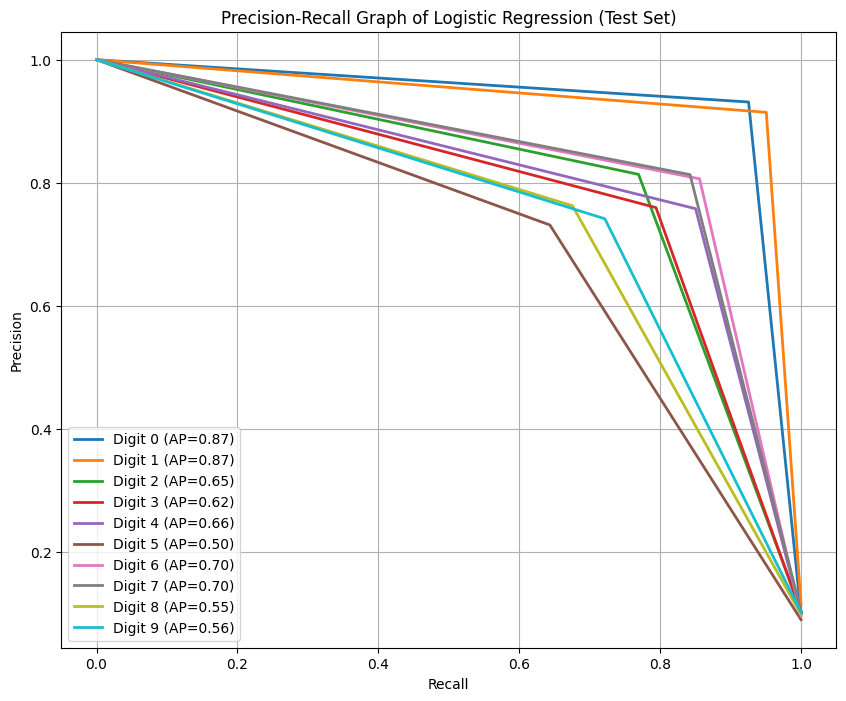

In [ ]:
plot_pr_curve(y_test, y_pred_cv_lr_test, "Precision-Recall Graph of Logistic Regression (Test Set)")

### **2.2.6 Performance measure: ROC curve**

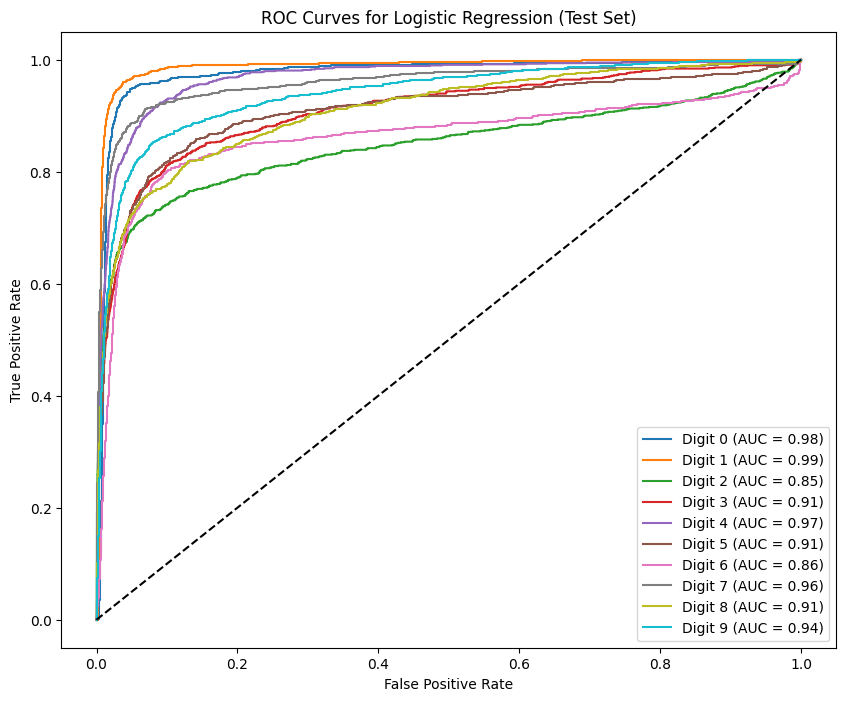

In [ ]:
plot_roc_curve(best_model_lr, 'ROC Curves for Logistic Regression (Test Set)')

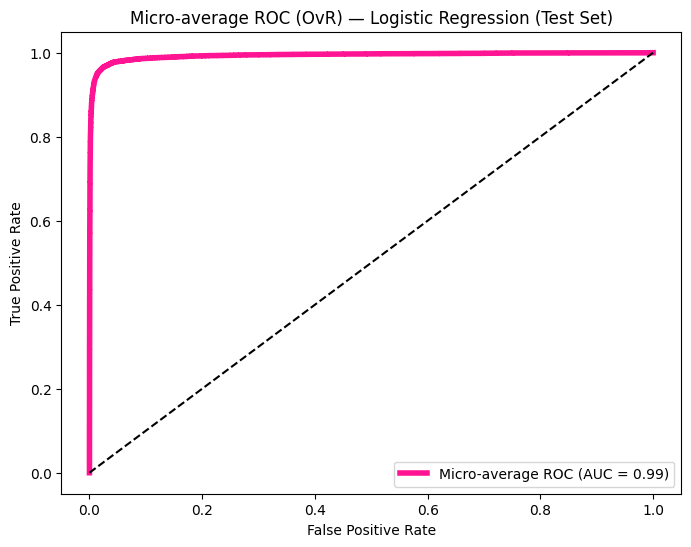

In [ ]:
# Plot Micro-average ROC for Logistic Regression on Test Set
plot_roc_microavg(best_model_lr, X_test, y_test,
                  title="Micro-average ROC (OvR) — Logistic Regression (Test Set)")

### **2.2.7 Performance measure: Visualizing Correct and Incorrect Classification**

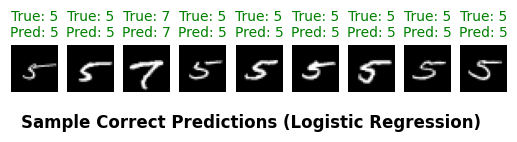

In [ ]:
display_correct_classifications(y_test_pred_lr, 'Sample Correct Predictions (Logistic Regression)')

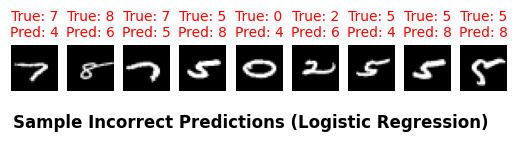

In [ ]:
display_incorrect_classifications(y_test_pred_lr, 'Sample Incorrect Predictions (Logistic Regression)')

### **2.2.8 Performance measure: Visualizing multiple chart for more insights**

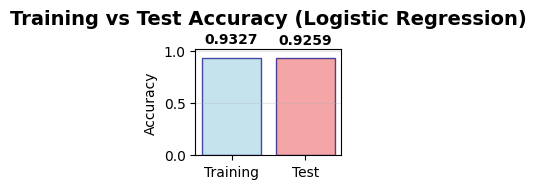

In [ ]:
plot_training_test_accuracy(best_model_lr, 'Training vs Test Accuracy (Logistic Regression)')

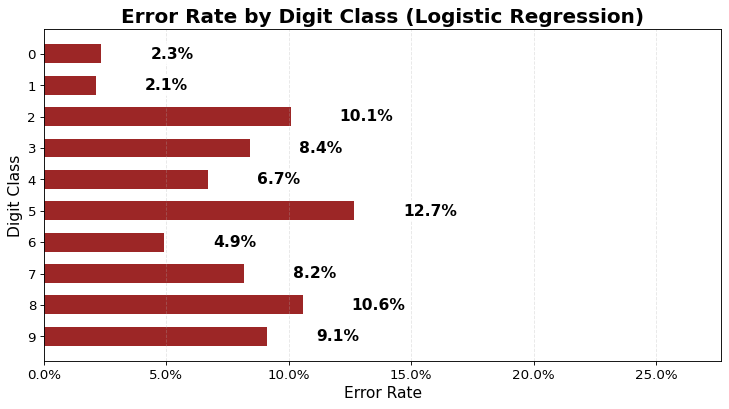

In [ ]:
plot_error_rate_by_digit(y_test_pred_lr, 'Error Rate by Digit Class (Logistic Regression)')

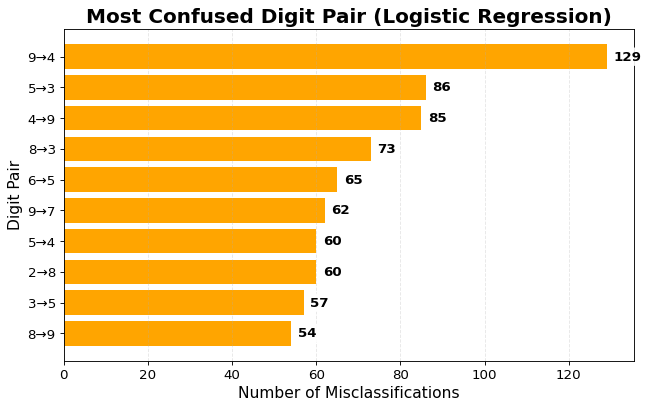

In [ ]:
plot_most_confused_digit_pair(cm_lr_test_cv, 'Most Confused Digit Pair (Logistic Regression)')

In [ ]:
# Perform 5-fold cross-validation
cv_scores_lr = cross_val_score(lr_model, X_train, y_train, cv=5, scoring='accuracy', n_jobs=-1)

print(f"Cross-Validation Scores: {cv_scores_lr}")
print(f"Mean CV Accuracy: {cv_scores_lr.mean():.4f} ")

Cross-Validation Scores: [0.68083333 0.86591667 0.888      0.88383333 0.57816667]
Mean CV Accuracy: 0.7793 


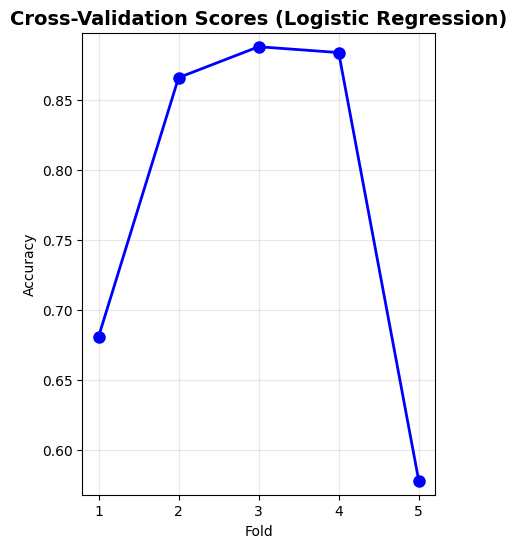

In [ ]:
plot_cv_scores("Cross-Validation Scores (Logistic Regression)", cv_scores_lr)

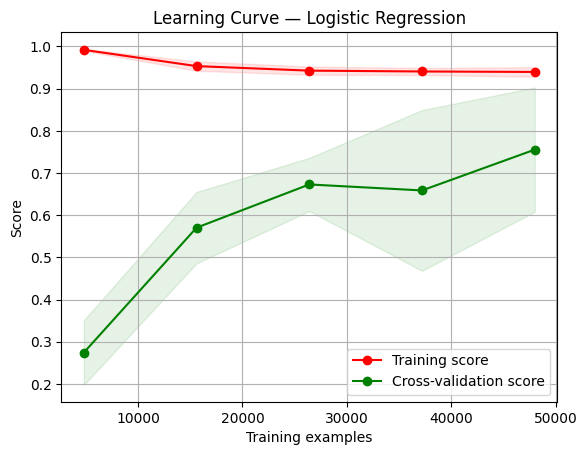

In [ ]:
# Plot Learning Curve for Logistic Regression
plot_learning_curve(best_model_lr, X_train, y_train,
                    title="Learning Curve — Logistic Regression", cv=5, n_jobs=-1)
plt.show() # Added plt.show() to display the plot

In [ ]:
print("\n" + "="*60)
print("LOGISTIC REGRESSION MODEL SUMMARY")
print("="*60)

print(f"Dataset: MNIST Handwritten Digits")
print(f"Training Samples: {len(X_train)}")
print(f"Test Samples: {len(X_test)}")
print(f"Number of Features: {X_train.shape[1]}")
print(f"Number of Classes: 10")
print()
print(f"Model Performance:")
print(f"  • Training Accuracy: {train_accuracy_lr:.4f} ({train_accuracy_lr*100:.2f}%)")
print(f"  • Test Accuracy: {test_accuracy_lr:.4f} ({test_accuracy_lr*100:.2f}%)")
print(f"  • Cross-Validation Score: {cv_scores_lr.mean():.4f} (±{cv_scores_lr.std()*2:.4f})")
print()
print(f"Model Characteristics:")
print(f"  • Solver: lbfgs")
print(f"  • Multi-class Strategy: One-vs-Rest")
print(f"  • Regularization: L2")
print(f"  • Max Iterations: 1000")



LOGISTIC REGRESSION MODEL SUMMARY
Dataset: MNIST Handwritten Digits
Training Samples: 60000
Test Samples: 10000
Number of Features: 784
Number of Classes: 10

Model Performance:
  • Training Accuracy: 0.9327 (93.27%)
  • Test Accuracy: 0.9259 (92.59%)
  • Cross-Validation Score: 0.7793 (±0.2536)

Model Characteristics:
  • Solver: lbfgs
  • Multi-class Strategy: One-vs-Rest
  • Regularization: L2
  • Max Iterations: 1000


In [ ]:
# Find best and worst performing digits using F1-Score from metrics_df
if 'metrics_df_lr' in globals():
    # Find the index of the best and worst F1-scores
    best_digit_idx = metrics_df_lr['F1-Score'].argmax()
    worst_digit_idx = metrics_df_lr['F1-Score'].argmin()

    # Get the digit label and the corresponding F1-score
    best_digit = metrics_df_lr['Digit'][best_digit_idx]
    best_f1 = metrics_df_lr['F1-Score'][best_digit_idx]

    worst_digit = metrics_df_lr['Digit'][worst_digit_idx]
    worst_f1 = metrics_df_lr['F1-Score'][worst_digit_idx]

    print(f"  • Best Recognized Digit (based on F1-Score): {best_digit} ({best_f1:.4f} F1-score)")
    print(f"  • Most Challenging Digit (based on F1-Score): {worst_digit} ({worst_f1:.4f} F1-score)")
else:
    print("Error: metrics_df DataFrame not found. Please run the cell that generates metrics_df first.")

  • Best Recognized Digit (based on F1-Score): 1 (0.9703 F1-score)
  • Most Challenging Digit (based on F1-Score): 8 (0.8865 F1-score)


## **2.3 Support Vector Machine**

### **2.3.1 Training model**

In [ ]:
from sklearn.svm import SVC

# Initialize SVM model
svm_model = SVC(kernel="linear", random_state=42)

# Train the model
print("Training in progress... This may take a few minutes.")
svm_model.fit(X_train, y_train)
print("✓ Model training completed!")

Training in progress... This may take a few minutes.
✓ Model training completed!


In [ ]:
# Make predictions on training and test sets
y_train_pred_svm = svm_model.predict(X_train)
y_test_pred_svm = svm_model.predict(X_test)

# Calculate accuracies
train_accuracy = accuracy_score(y_train, y_train_pred_svm)
test_accuracy = accuracy_score(y_test, y_test_pred_svm)

print(f"Training Accuracy: {train_accuracy:.4f} ({train_accuracy*100:.2f}%)")
print(f"Test Accuracy: {test_accuracy:.4f} ({test_accuracy*100:.2f}%)")
print(f"Overfitting Check: {abs(train_accuracy - test_accuracy):.4f}")

Training Accuracy: 0.9707 (97.07%)
Test Accuracy: 0.9404 (94.04%)
Overfitting Check: 0.0303


### **2.3.2 Fine-tune the model using Grid Search**

In [ ]:
from sklearn.model_selection import GridSearchCV
from sklearn.svm import SVC

# Smaller parameter grid
param_grid = {
    "C": [0.1, 1],             # reduced range
    "kernel": ["linear"],  #
    "gamma": ["scale"]        # only the default, skip "auto"
}

grid_search = GridSearchCV(
    SVC(),
    param_grid=param_grid,
    cv=3,
    scoring="accuracy",
    verbose=2,
    n_jobs=-1
)

grid_search.fit(X_train, y_train)

print("Best params:", grid_search.best_params_)
print(f"Best CV acc: {grid_search.best_score_:.4f}")



Fitting 3 folds for each of 2 candidates, totalling 6 fits
Best params: {'C': 0.1, 'gamma': 'scale', 'kernel': 'linear'}
Best CV acc: 0.7616


### **2.3.3 Performance measure: Precision, Recall and F1 Score**


In [ ]:
best_model_svm = grid_search.best_estimator_
y_pred_svm = best_model_svm.predict(X_test)

print("Test metrics (SVM):")
print("  Acc:", accuracy_score(y_test, y_pred_svm))
print("  Prec(macro):", precision_score(y_test, y_pred_svm, average="macro", zero_division=0))
print("  Rec(macro):",  recall_score(y_test, y_pred_svm, average="macro", zero_division=0))
print("  F1(macro):",   f1_score(y_test, y_pred_svm, average="macro", zero_division=0))

print("\nClassification report (SVM):\n", classification_report(y_test, y_pred_svm, digits=4, zero_division=0))

Test metrics (SVM):
  Acc: 0.9472
  Prec(macro): 0.9466135426108956
  Rec(macro): 0.9462820114039113
  F1(macro): 0.9463268295923545

Classification report (SVM):
               precision    recall  f1-score   support

           0     0.9622    0.9867    0.9743       980
           1     0.9791    0.9903    0.9847      1135
           2     0.9392    0.9438    0.9415      1032
           3     0.9128    0.9436    0.9279      1010
           4     0.9401    0.9593    0.9496       982
           5     0.9212    0.9047    0.9129       892
           6     0.9624    0.9614    0.9619       958
           7     0.9546    0.9416    0.9481      1028
           8     0.9377    0.9117    0.9245       974
           9     0.9567    0.9197    0.9378      1009

    accuracy                         0.9472     10000
   macro avg     0.9466    0.9463    0.9463     10000
weighted avg     0.9472    0.9472    0.9471     10000



In [ ]:
# Precision, Recall, F1-Score for each class
precision, recall, f1, support = precision_recall_fscore_support(y_test, y_test_pred_svm)

# Create a summary DataFrame
metrics_df_svm = pd.DataFrame({
    'Digit': range(10),
    'Precision': precision,
    'Recall': recall,
    'F1-Score': f1,
    'Support': support
})

print("\nPer-Class Metrics (SVM):")
print(metrics_df_svm.round(4))



Per-Class Metrics (SVM):
   Digit  Precision  Recall  F1-Score  Support
0      0     0.9522  0.9765    0.9642      980
1      1     0.9697  0.9885    0.9791     1135
2      2     0.9254  0.9370    0.9312     1032
3      3     0.9062  0.9376    0.9217     1010
4      4     0.9364  0.9593    0.9477      982
5      5     0.9146  0.9002    0.9073      892
6      6     0.9569  0.9499    0.9534      958
7      7     0.9522  0.9309    0.9415     1028
8      8     0.9370  0.9004    0.9183      974
9      9     0.9486  0.9138    0.9308     1009


In [ ]:
print("Precision (macro) = {:.4f}".format(precision_score(y_test, y_test_pred_svm, average='macro')))
print("Recall    (macro) = {:.4f}".format(recall_score(y_test, y_test_pred_svm, average='macro')))
print("F1 score  (macro) = {:.4f}".format(f1_score(y_test, y_test_pred_svm, average='macro')))

Precision (macro) = 0.9399
Recall    (macro) = 0.9394
F1 score  (macro) = 0.9395


In [ ]:
# Make predictions on training and test sets
y_train_pred_svm = best_model_svm.predict(X_train)
y_test_pred_svm = best_model_svm.predict(X_test)

# Calculate accuracies
train_accuracy_svm = accuracy_score(y_train, y_train_pred_svm)
test_accuracy_svm = accuracy_score(y_test, y_test_pred_svm)

print(f"Training Accuracy: {train_accuracy_svm:.4f} ({train_accuracy_svm*100:.2f}%)")
print(f"Test Accuracy: {test_accuracy_svm:.4f} ({test_accuracy_svm*100:.2f}%)")
print(f"Overfitting Check: {abs(train_accuracy_svm - test_accuracy_svm):.4f}%")

Training Accuracy: 0.9588 (95.88%)
Test Accuracy: 0.9472 (94.72%)
Overfitting Check: 0.0116%


### **2.3.4 Performance measure: Confusion Matrix**

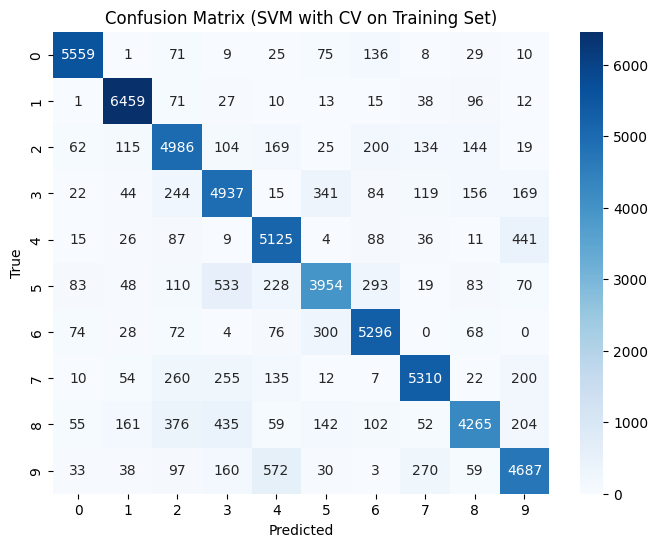

In [ ]:
# Cross-val predict of training data using SVM
y_pred_cv_svm_train = cross_val_predict(best_model_svm, X_train, y_train, cv=5)

# Compute confusion matrix
cm_svm_train_cv = confusion_matrix(y_train, y_pred_cv_svm_train)
show_matrix(cm_svm_train_cv, class_names=[str(i) for i in range(10)],
            title="Confusion Matrix (SVM with CV on Training Set)")

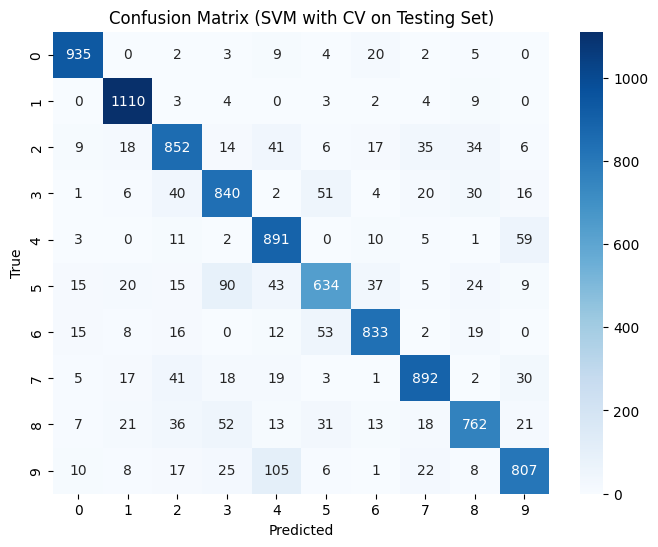

In [ ]:
# Cross-val predict of testing data using SVM
y_pred_cv_svm_test = cross_val_predict(best_model_svm, X_test, y_test, cv=5)

# Compute confusion matrix
cm_svm_test_cv = confusion_matrix(y_test, y_pred_cv_svm_test)
show_matrix(cm_svm_test_cv, class_names=[str(i) for i in range(10)],
            title="Confusion Matrix (SVM with CV on Testing Set)")

### **2.3.5 Performance Measure: Precision-Recall curve**

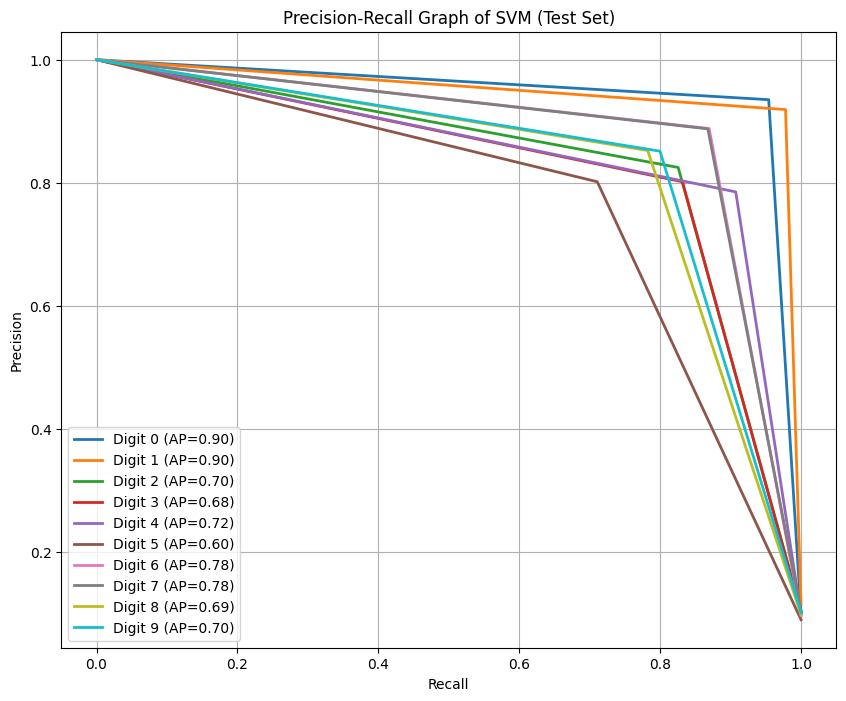

In [ ]:
plot_pr_curve(y_test, y_pred_cv_svm_test, "Precision-Recall Graph of SVM (Test Set)")

### **2.3.6 Performance measure: ROC curve**

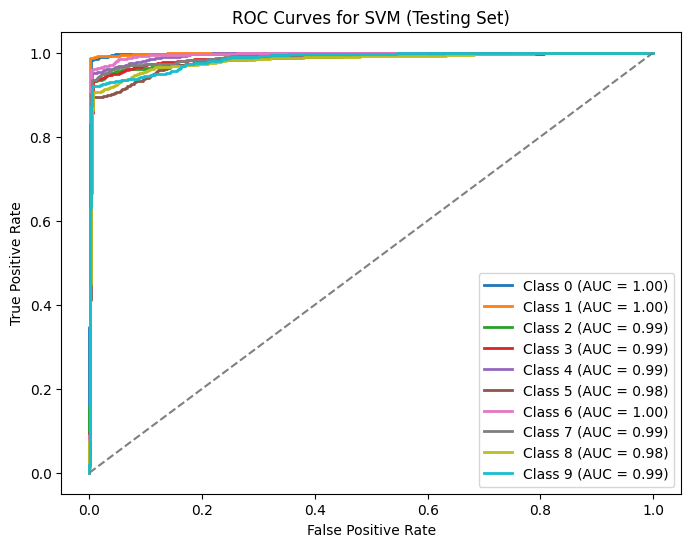

In [ ]:
plot_roc_curve_decision(best_model_svm, X_test, y_test,
                        "ROC Curves for SVM (Testing Set)")


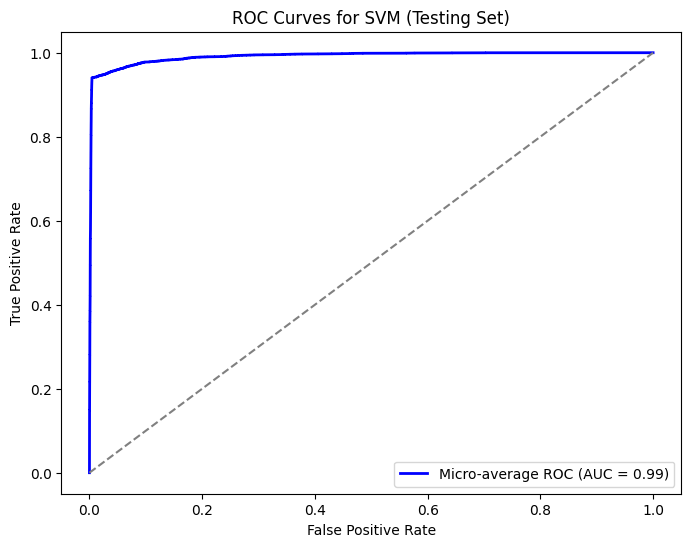

In [ ]:
plot_roc_microavg_decision(best_model_svm, X_test, y_test,
                        "ROC Curves for SVM (Testing Set)")

### **2.3.7 Performance measure: Visualizing Correct and Incorrect Classification**

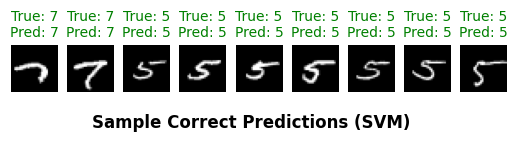

In [ ]:
display_correct_classifications(y_test_pred_svm, 'Sample Correct Predictions (SVM)')

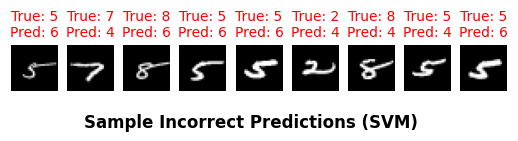

In [ ]:
display_incorrect_classifications(y_test_pred_svm, 'Sample Incorrect Predictions (SVM)')

### **2.3.8 Performance measure: Visualizing multiple chart for more insights**

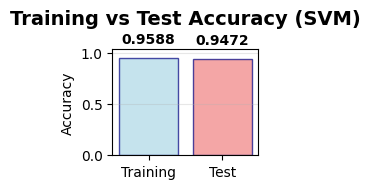

In [ ]:
plot_training_test_accuracy(best_model_svm, 'Training vs Test Accuracy (SVM)')

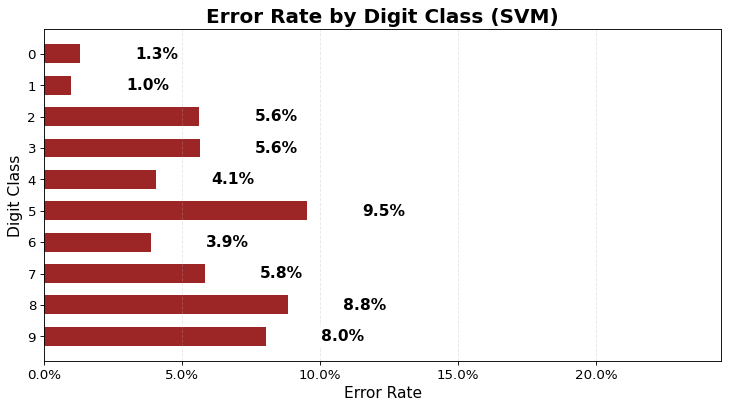

In [ ]:
plot_error_rate_by_digit(y_test_pred_svm, 'Error Rate by Digit Class (SVM)')

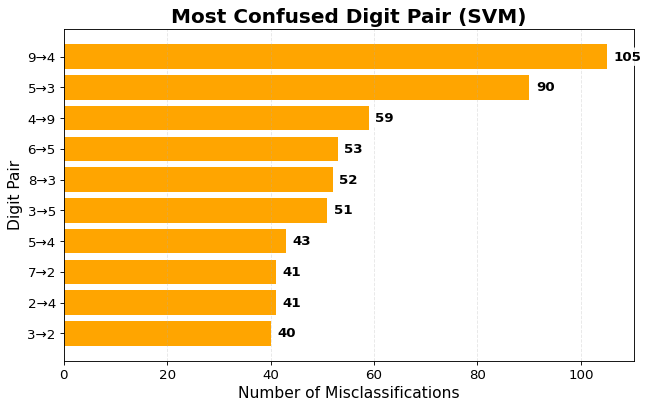

In [ ]:
plot_most_confused_digit_pair(cm_svm_test_cv, 'Most Confused Digit Pair (SVM)')

In [ ]:
# Perform 5-fold cross-validation
cv_scores_svm = cross_val_score(best_model_svm, X_test, y_test, cv=5, scoring='accuracy', n_jobs=-1)

print(f"Cross-Validation Scores: {cv_scores_svm}")
print(f"Mean CV Accuracy: {cv_scores_svm.mean():.4f} ")

Cross-Validation Scores: [0.7285 0.925  0.932  0.9245 0.768 ]
Mean CV Accuracy: 0.8556 


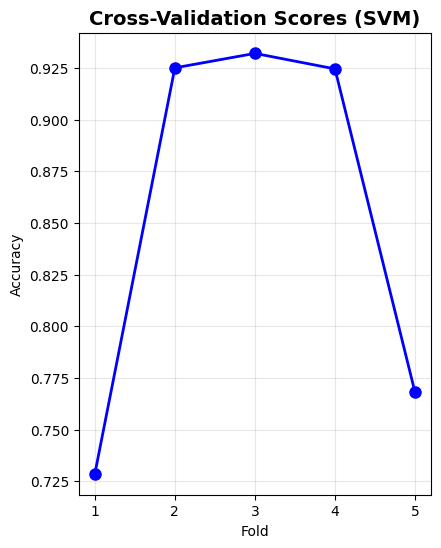

In [ ]:
plot_cv_scores("Cross-Validation Scores (SVM)", cv_scores_svm)

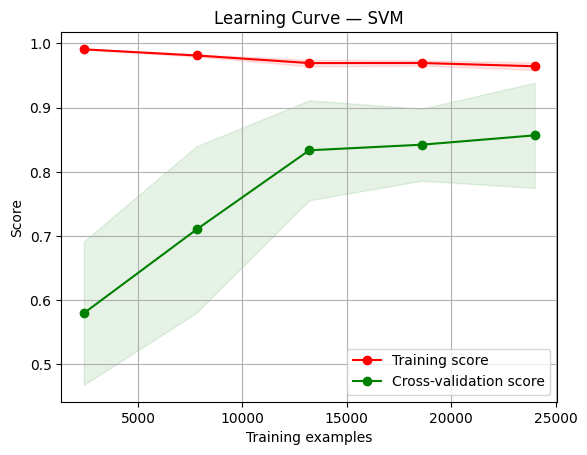

In [ ]:
# Plot Learning Curve for SVM
plot_learning_curve(best_model_svm, X_train[:30000], y_train[:30000],
                    title="Learning Curve — SVM", cv=5, n_jobs=-1)
plt.show() # Added plt.show() to display the plot

In [ ]:
print("\n" + "="*60)
print("SUPPORT VECTOR MACHINE MODEL SUMMARY")
print("="*60)

print(f"Dataset: MNIST Handwritten Digits")
print(f"Training Samples: {len(X_train)}")
print(f"Test Samples: {len(X_test)}")
print(f"Number of Features: {X_train.shape[1]}")
print(f"Number of Classes: 10")
print()
print("Model Performance:")
print(f"  • Training Accuracy: {train_accuracy_svm:.4f} ({train_accuracy_svm*100:.2f}%)")
print(f"  • Test Accuracy: {test_accuracy_svm:.4f} ({test_accuracy_svm*100:.2f}%)")
print(f"  • Cross-Validation Score: {cv_scores_svm.mean():.4f} (±{cv_scores_svm.std()*2:.4f})")
print()
print("Model Characteristics:")
print(f"  • Kernel: {best_model_svm.kernel}")
print(f"  • Regularization Parameter (C): {best_model_svm.C}")
print(f"  • Gamma: {best_model_svm.gamma}")




SUPPORT VECTOR MACHINE MODEL SUMMARY
Dataset: MNIST Handwritten Digits
Training Samples: 60000
Test Samples: 10000
Number of Features: 784
Number of Classes: 10

Model Performance:
  • Training Accuracy: 0.9588 (95.88%)
  • Test Accuracy: 0.9472 (94.72%)
  • Cross-Validation Score: 0.8556 (±0.1772)

Model Characteristics:
  • Kernel: linear
  • Regularization Parameter (C): 0.1
  • Gamma: scale


In [ ]:
# Find best and worst performing digits using F1-Score from metrics_df
if 'metrics_df_svm' in globals():
    # Find the index of the best and worst F1-scores
    best_digit_idx = metrics_df_svm['F1-Score'].argmax()
    worst_digit_idx = metrics_df_svm['F1-Score'].argmin()

    # Get the digit label and the corresponding F1-score
    best_digit = metrics_df_svm['Digit'][best_digit_idx]
    best_f1 = metrics_df_svm['F1-Score'][best_digit_idx]

    worst_digit = metrics_df_svm['Digit'][worst_digit_idx]
    worst_f1 = metrics_df_svm['F1-Score'][worst_digit_idx]

    print(f"  • Best Recognized Digit (based on F1-Score): {best_digit} ({best_f1:.4f} F1-score)")
    print(f"  • Most Challenging Digit (based on F1-Score): {worst_digit} ({worst_f1:.4f} F1-score)")
else:
    print("Error: metrics_df DataFrame not found. Please run the cell that generates metrics_df first.")

  • Best Recognized Digit (based on F1-Score): 1 (0.9791 F1-score)
  • Most Challenging Digit (based on F1-Score): 5 (0.9073 F1-score)


## **3.0 Comparing Classifiers**

### **3.1 Performance measure: Fair Comparision Using 3-fold OOF ROC/AUC**

In [ ]:
# Use tuned models for ROC/AUC (if available else fallback)
# Common preproc
flatten = FunctionTransformer(lambda X: X.reshape(X.shape[0], -1), validate=False)

# Fallback (if no GridSearch objects are found)
pipe_lr_default = Pipeline([
    ("flatten", flatten),
    ("scaler", StandardScaler(with_mean=False)),
    ("clf", LogisticRegression(multi_class="multinomial", solver="lbfgs", max_iter=300, tol=1e-3, C=1.0)),
])
pipe_knn_default = Pipeline([
    ("flatten", flatten),
    ("scaler", StandardScaler(with_mean=False)),
    ("clf", KNeighborsClassifier(n_neighbors=5, weights="distance")),
])
pipe_svm_default = Pipeline([
    ("flatten", flatten),
    ("scaler", StandardScaler(with_mean=False)),
    ("clf", SVC(kernel="rbf", C=1.0, gamma="scale")),  # decision_function used for ROC
])

def resolve_model(obj_or_name, fallback):
    """
    Accepts either a string (variable name) or an object.
    - If it's a GridSearchCV with best_estimator_, returns a clone of best_estimator_.
    - If it's already an estimator/pipeline (has fit + predict/proba/decision_function), returns a clone of it.
    - Otherwise returns fallback.
    """
    # Look up by name if a string is passed
    obj = globals().get(obj_or_name) if isinstance(obj_or_name, str) else obj_or_name

    if obj is None:
        print(f"[resolve_model] {obj_or_name} not found -> using fallback")
        return fallback

    # GridSearchCV case
    if hasattr(obj, "best_estimator_"):
        return clone(obj.best_estimator_)

    # Already an estimator/pipeline
    if hasattr(obj, "fit") and (hasattr(obj, "predict_proba") or hasattr(obj, "decision_function") or hasattr(obj, "predict")):
        return clone(obj)

    print(f"[resolve_model] {obj_or_name} not usable -> using fallback")
    return fallback

lr_model  = resolve_model("best_model_lr",  pipe_lr_default)
knn_model = resolve_model("best_model_knn", pipe_knn_default)
svm_model = resolve_model("best_model_svm", pipe_svm_default)

models = {"k-NN": knn_model, "Logistic Regression": lr_model, "SVM": svm_model}

# 3-fold OOF ROC/AUC
cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)
classes = np.unique(y_train)
y_bin = label_binarize(y_train, classes=classes)

def oof_scores(est, X, y):
    # prefer predict_proba; fall back to decision_function
    last = est.steps[-1][1] if hasattr(est, "steps") else est
    method = "predict_proba" if hasattr(last, "predict_proba") else "decision_function"
    scores = cross_val_predict(est, X, y, cv=cv, method=method, n_jobs=-1)
    scores = np.asarray(scores)
    if scores.ndim == 1:  # binary safety
        scores = np.vstack([1 - scores, scores]).T
    return scores

roc_oof = {}
rows = []
for name, est in models.items():
    print(f"OOF scoring for {name} ...", end="")
    s = oof_scores(est, X_train, y_train)
    print("done")
    fpr, tpr, _ = roc_curve(y_bin.ravel(), s.ravel())
    auc_micro = roc_auc_score(y_bin, s, average="micro", multi_class="ovr")
    auc_macro = roc_auc_score(y_bin, s, average="macro", multi_class="ovr")
    y_pred_oof = cross_val_predict(est, X_train, y_train, cv=cv, method="predict", n_jobs=-1)
    acc_cv = accuracy_score(y_train, y_pred_oof)
    f1_cv  = f1_score(y_train, y_pred_oof, average="macro", zero_division=0)
    roc_oof[name] = (fpr, tpr, auc_micro, auc_macro)
    rows.append([name, acc_cv, f1_cv, auc_micro, auc_macro])

cv_table = pd.DataFrame(rows, columns=["Model","CV Acc","CV F1 (macro)","OOF AUC micro","OOF AUC macro"])
print("\n3-fold OOF ROC (3 fold OOF for Tuned Models)")
print(cv_table.sort_values("CV F1 (macro)", ascending=False).round(4))


OOF scoring for k-NN ...done
OOF scoring for Logistic Regression ...done
OOF scoring for SVM ...done

3-fold OOF ROC (3 fold OOF for Tuned Models)
                 Model  CV Acc  CV F1 (macro)  OOF AUC micro  OOF AUC macro
0                 k-NN  0.9719         0.9718         0.9946         0.9945
2                  SVM  0.9398         0.9389         0.9905         0.9891
1  Logistic Regression  0.9188         0.9178         0.9922         0.9915


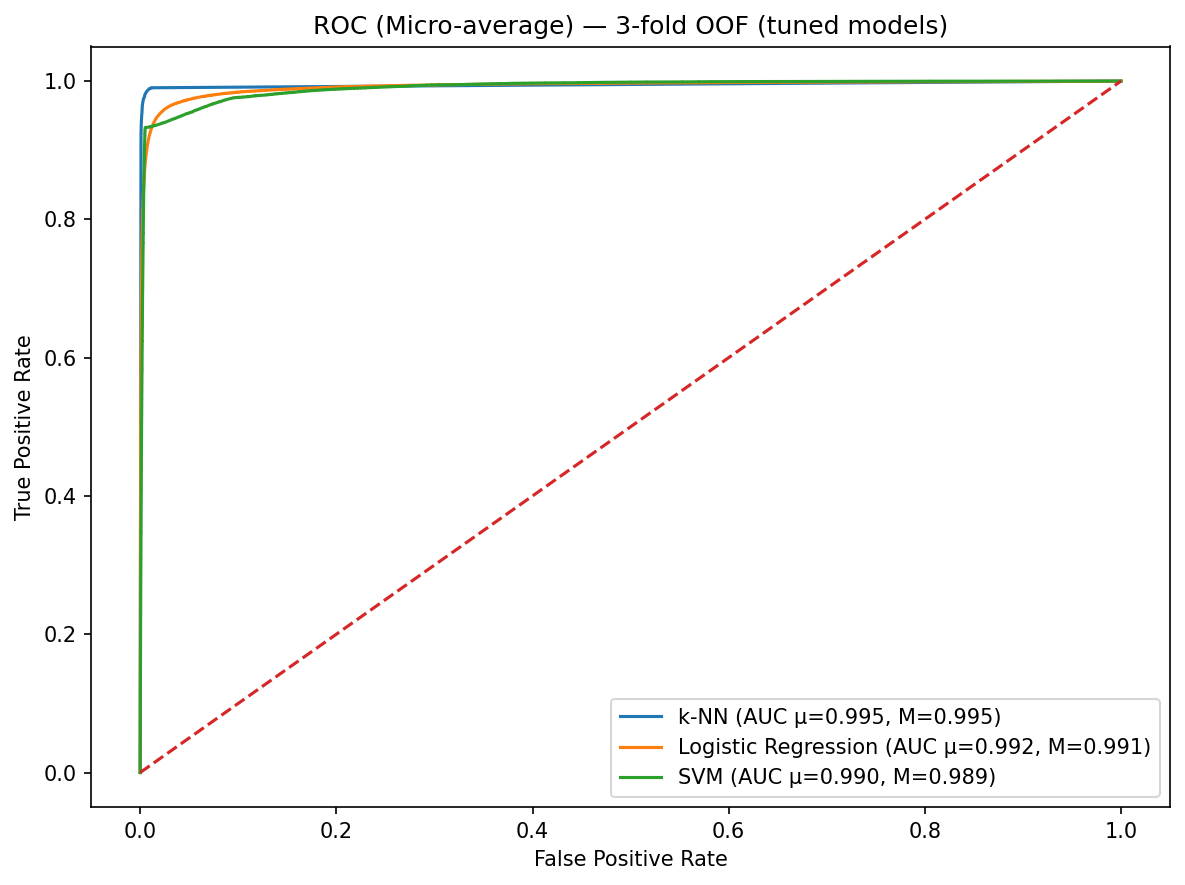

In [ ]:
plt.figure(figsize=(8,6), dpi=150)
for name, (fpr, tpr, amicro, amacro) in roc_oof.items():
    plt.plot(fpr, tpr, label=f"{name} (AUC μ={amicro:.3f}, M={amacro:.3f})")
plt.plot([0,1],[0,1],"--")
plt.title("ROC (Micro-average) — 3-fold OOF (tuned models)")
plt.xlabel("False Positive Rate"); plt.ylabel("True Positive Rate")
plt.legend(loc="lower right"); plt.tight_layout(); plt.show()

### **3.2 Performance measure: ROC/AUC on Test Set**

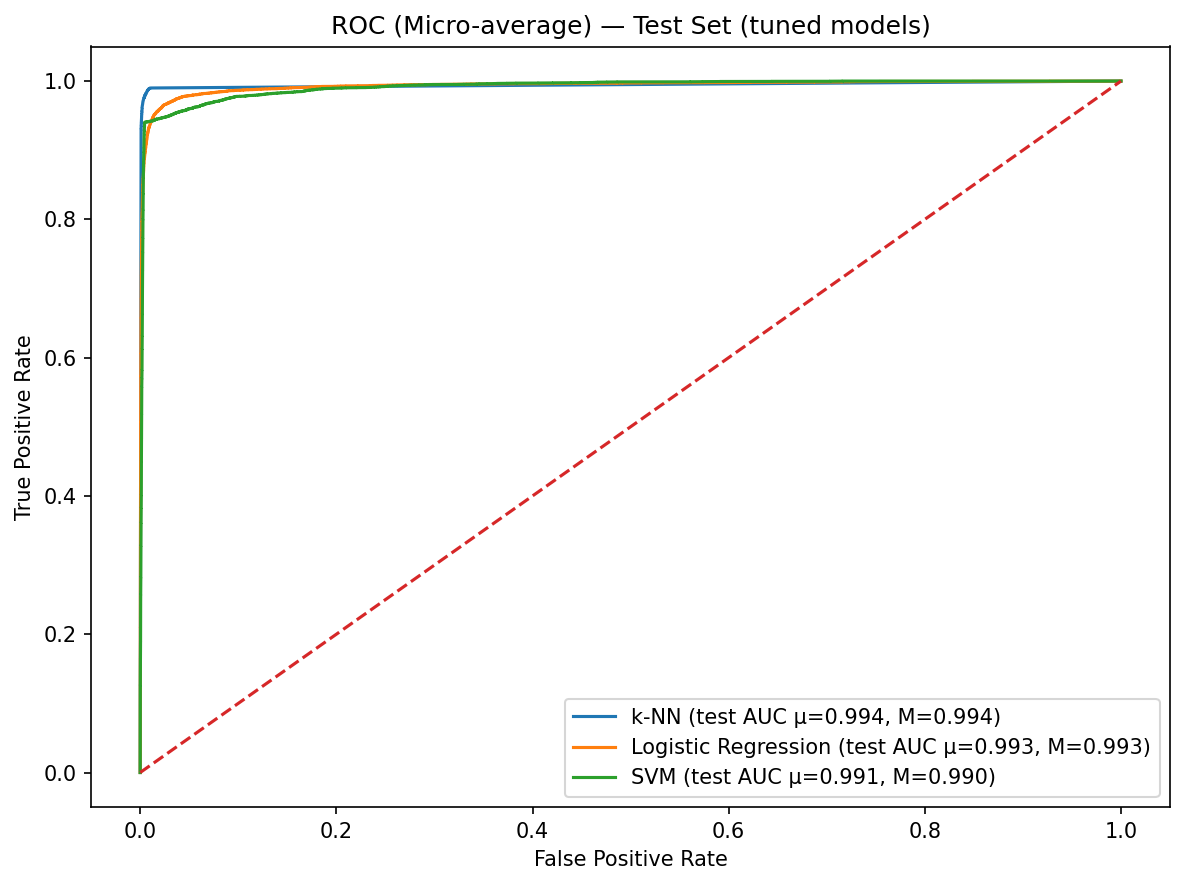

In [ ]:
# Final Test ROC/AUC fit tuned models on all training data
rows_test = []
scores_by_model = {}

plt.figure(figsize=(8,6), dpi=150)
for name, est in models.items():
    est.fit(X_train, y_train)
    last = est.steps[-1][1] if hasattr(est, "steps") else est
    s = est.predict_proba(X_test) if hasattr(last, "predict_proba") else est.decision_function(X_test)
    s = np.asarray(s)
    if s.ndim == 1:
        s = np.vstack([1 - s, s]).T

    scores_by_model[name] = s

    classes = np.unique(y_test)
    y_bin_test = label_binarize(y_test, classes=classes)

    fpr, tpr, _ = roc_curve(y_bin_test.ravel(), s.ravel())
    auc_micro = roc_auc_score(y_bin_test, s, average="micro", multi_class="ovr")
    auc_macro = roc_auc_score(y_bin_test, s, average="macro", multi_class="ovr")
    plt.plot(fpr, tpr, label=f"{name} (test AUC μ={auc_micro:.3f}, M={auc_macro:.3f})")
    rows_test.append([name, auc_micro, auc_macro])

plt.plot([0,1],[0,1],"--")
plt.title("ROC (Micro-average) — Test Set (tuned models)")
plt.xlabel("False Positive Rate"); plt.ylabel("True Positive Rate")
plt.legend(loc="lower right"); plt.tight_layout(); plt.show()


In [ ]:
print("Test ROC/AUC fit tuned models on all training data")
print(pd.DataFrame(rows_test, columns=["Model","Test AUC micro","Test AUC macro"]).round(4))

Test ROC/AUC fit tuned models on all training data
                 Model  Test AUC micro  Test AUC macro
0                 k-NN          0.9944          0.9944
1  Logistic Regression          0.9933          0.9926
2                  SVM          0.9914          0.9902


### **3.3 Performance measure: Basic Performance Metrics Comparison on Test Set**

In [ ]:
model_names = ['k-NN', 'Logistic Regression', 'SVM']
predictions = {
    'k-NN': y_test_pred_knn,
    'Logistic Regression': y_test_pred_lr,
    'SVM': y_test_pred_svm
}

In [ ]:
print("Basic Performance Metrics Comparison...")
# Calculate metrics for all models
metrics_data = []
for model_name in model_names:
    y_pred = predictions[model_name]

    # Calculate metrics
    accuracy = accuracy_score(y_test, y_pred)
    precision = precision_score(y_test, y_pred, average='weighted')
    recall = recall_score(y_test, y_pred, average='weighted')
    f1 = f1_score(y_test, y_pred, average='weighted')

    metrics_data.append({
        'Model': model_name,
        'Accuracy': accuracy,
        'Precision': precision,
        'Recall': recall,
        'F1-Score': f1
    })

# Create comparison DataFrame
metrics_df = pd.DataFrame(metrics_data)
print("\nPerformance Metrics Comparison:")
print("=" * 100)
print(metrics_df.round(4).to_string(index=False))

Basic Performance Metrics Comparison...

Performance Metrics Comparison:
              Model  Accuracy  Precision  Recall  F1-Score
               k-NN    0.9714     0.9715  0.9714    0.9714
Logistic Regression    0.9259     0.9258  0.9259    0.9258
                SVM    0.9472     0.9472  0.9472    0.9471


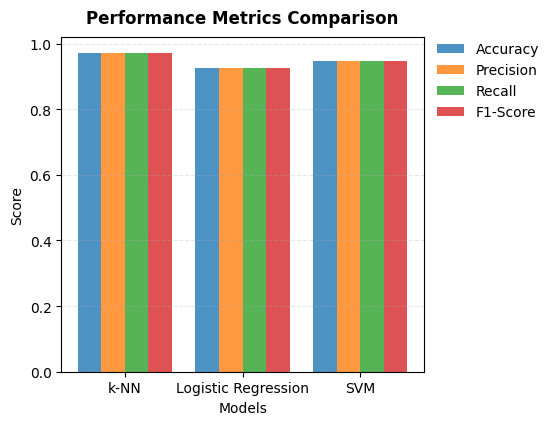

In [ ]:
# Create a comprehensive comparison plot
fig = plt.figure(figsize=(24, 20))

# Performance Metrics Bar Chart
ax = plt.subplot(4, 4, 1)

metrics_to_plot = ['Accuracy', 'Precision', 'Recall', 'F1-Score']
x = np.arange(len(model_names))
width = 0.2

for i, metric in enumerate(metrics_to_plot):
    values = [metrics_df[metrics_df['Model'] == m][metric].iloc[0] for m in model_names]
    ax.bar(x + i*width, values, width, label=metric, alpha=0.8)

ax.set_xlabel('Models')
ax.set_ylabel('Score')
ax.set_title('Performance Metrics Comparison', fontweight='bold', pad=10)
ax.set_xticks(x + width*1.5)
ax.set_xticklabels(model_names)
ax.grid(axis='y', alpha=0.3, linestyle='--')

# 👉 move legend outside, on the right
ax.legend(loc='upper left', bbox_to_anchor=(1.02, 1.0), borderaxespad=0., frameon=False)

# 👉 make room on the right so legend isn't clipped
ax.figure.subplots_adjust(right=0.82)
# (or instead of the line above, you can use: plt.tight_layout(rect=[0, 0, 0.82, 1]))


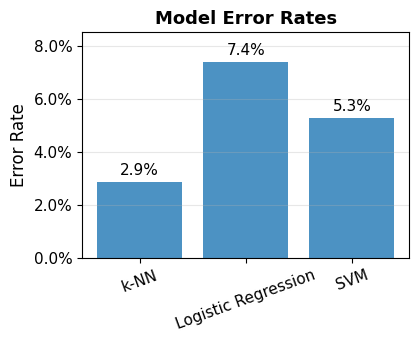

In [ ]:
# Plot each model error rates
fig = plt.gcf()
fig.set_size_inches(16, 12)

ax = plt.subplot(4, 4, 11)

error_rates = []
for model_name in model_names:
    error_rate = 1 - accuracy_score(y_test, predictions[model_name])
    error_rates.append(error_rate)

bars = ax.bar(model_names, error_rates, alpha=0.8)

ax.set_ylabel('Error Rate', fontsize=12)
ax.set_title('Model Error Rates', fontweight='bold', fontsize=13)

# Format y as percentages and add a little headroom
ax.yaxis.set_major_formatter(mtick.PercentFormatter(1.0))
ax.set_ylim(0, max(error_rates) * 1.15)

# Ticks: rotate x labels and bump font sizes
ax.tick_params(axis='x', labelrotation=20, labelsize=11)
ax.tick_params(axis='y', labelsize=11)
ax.grid(axis='y', alpha=0.3)

# Value labels on top of bars (as %)
for bar, err in zip(bars, error_rates):
    ax.annotate(f'{err:.1%}',
                xy=(bar.get_x() + bar.get_width()/2, bar.get_height()),
                xytext=(0, 3), textcoords='offset points',
                ha='center', va='bottom', fontsize=11)

fig.tight_layout()


In [ ]:
# Per-Class AUCs from test scores
classes = np.unique(y_test)
y_bin_test = label_binarize(y_test, classes=classes)

per_class_auc = {
    name: roc_auc_score(y_bin_test, scores_by_model[name], average=None, multi_class="ovr")
    for name in models.keys()
}

# Per-Class Performance Analysis
print("\nPer-Class Performance Analysis:")
print("=" * 80)

per_class_data = []
for model_name_display in model_names:
    # Find the corresponding model key in the 'models' dictionary
    model_key = None
    for key, value in models.items():
        if model_name_display in key or key in model_name_display: # Check for substring match (e.g., 'k-NN' in 'kNN')
             model_key = key
             break

    if model_key is None:
        print(f"Warning: Could not find model key for display name '{model_name_display}'")
        continue

    y_pred = predictions[model_name_display]
    report = classification_report(y_test, y_pred, output_dict=True)

    for idx, digit in enumerate(classes):
        per_class_data.append({
            'Model': model_name_display,
            'Digit': int(digit),
            'Precision': report[str(digit)]['precision'],
            'Recall': report[str(digit)]['recall'],
            'F1-Score': report[str(digit)]['f1-score'],
            'Support': report[str(digit)]['support'],
            'AUC': float(per_class_auc[model_key][idx])
        })

per_class_df = pd.DataFrame(per_class_data)

print("\nBest Performing Model for Each Digit (by F1-Score):")
print("-" * 60)
for digit in classes:
    digit_data = per_class_df[per_class_df['Digit'] == digit]
    best_idx = digit_data['F1-Score'].idxmax()
    best_model = digit_data.loc[best_idx, 'Model']
    best_f1 = digit_data.loc[best_idx, 'F1-Score']
    print(f"Digit {int(digit)}: {best_model} (F1-Score: {best_f1:.4f})")


Per-Class Performance Analysis:

Best Performing Model for Each Digit (by F1-Score):
------------------------------------------------------------
Digit 0: k-NN (F1-Score: 0.9828)
Digit 1: SVM (F1-Score: 0.9847)
Digit 2: k-NN (F1-Score: 0.9741)
Digit 3: k-NN (F1-Score: 0.9663)
Digit 4: k-NN (F1-Score: 0.9714)
Digit 5: k-NN (F1-Score: 0.9647)
Digit 6: k-NN (F1-Score: 0.9829)
Digit 7: k-NN (F1-Score: 0.9632)
Digit 8: k-NN (F1-Score: 0.9659)
Digit 9: k-NN (F1-Score: 0.9584)


In [ ]:
# Model Strengths and Weaknesses
print("\n\nModel Strengths and Weaknesses Analysis:")
print("=" * 80)

for model_name in model_names:
    model_data = per_class_df[per_class_df['Model'] == model_name]
    best_digits = model_data.nlargest(3, 'F1-Score')['Digit'].tolist()
    worst_digits = model_data.nsmallest(3, 'F1-Score')['Digit'].tolist()

    print(f"\n{model_name}:")
    print(f"  • Best performing digits: {best_digits}")
    print(f"  • Most challenging digits: {worst_digits}")
    print(f"  • Average F1-Score: {model_data['F1-Score'].mean():.4f}")
    print(f"  • F1-Score Standard Deviation: {model_data['F1-Score'].std():.4f}")



Model Strengths and Weaknesses Analysis:

k-NN:
  • Best performing digits: [6, 0, 1]
  • Most challenging digits: [9, 7, 5]
  • Average F1-Score: 0.9712
  • F1-Score Standard Deviation: 0.0090

Logistic Regression:
  • Best performing digits: [1, 0, 6]
  • Most challenging digits: [8, 5, 9]
  • Average F1-Score: 0.9249
  • F1-Score Standard Deviation: 0.0291

SVM:
  • Best performing digits: [1, 0, 6]
  • Most challenging digits: [5, 8, 3]
  • Average F1-Score: 0.9463
  • F1-Score Standard Deviation: 0.0224


### **3.4 Performance measure: Comprehensive Comparison**

In [ ]:
# Build test AUC df from rows_test
test_auc_df = pd.DataFrame(rows_test, columns=["Model","Test AUC micro","Test AUC macro"])

test_auc_df = test_auc_df.rename(columns={
    "Test AUC micro": "Micro-Avg AUC",
    "Test AUC macro": "Macro-Avg AUC",
})

# Ensure model names are consistent and in a fixed order
name_order = ["k-NN", "Logistic Regression", "SVM"]
test_auc_df = test_auc_df.set_index("Model").reindex(name_order).reset_index()

# Merge with your metrics (Accuracy, F1-Score)
needed_cols = ["Model", "Accuracy", "F1-Score"]
metrics_core = metrics_df[needed_cols].copy()
metrics_core = metrics_core.set_index("Model").reindex(name_order).reset_index()

ranking_df = metrics_core.merge(
    test_auc_df[["Model","Micro-Avg AUC","Macro-Avg AUC"]],
    on="Model", how="inner"
)

# Create Comprehensive Comparison with Rank (higher = better)
ranking_metrics = ["Accuracy", "Macro-Avg AUC", "Micro-Avg AUC", "F1-Score"]
for m in ranking_metrics:
    ranking_df[f"{m}_rank"] = ranking_df[m].rank(ascending=False, method="average")

ranking_df["Final_Rank"] = ranking_df[[f"{m}_rank" for m in ranking_metrics]].mean(axis=1)

final_ranking = (ranking_df
                 .sort_values("Final_Rank")
                 [["Model","Accuracy","Macro-Avg AUC","Micro-Avg AUC","F1-Score","Final_Rank"]])

print("\nFinal Model Ranking:")
print("="*100)
print(final_ranking.round(4).to_string(index=False))



Final Model Ranking:
              Model  Accuracy  Macro-Avg AUC  Micro-Avg AUC  F1-Score  Final_Rank
               k-NN    0.9714         0.9944         0.9944    0.9714         1.0
Logistic Regression    0.9259         0.9926         0.9933    0.9258         2.5
                SVM    0.9472         0.9902         0.9914    0.9471         2.5


In [ ]:
print("COMPREHENSIVE MODEL COMPARISON SUMMARY")
print("="*80)

best_model = ranking_df.loc[ranking_df['Final_Rank'].idxmin(), 'Model']
print(f"\nBEST OVERALL MODEL: {best_model}")

print(f"\nKEY FINDINGS:")
for i, (_, row) in enumerate(ranking_df.sort_values('Final_Rank').iterrows(), 1):
    model = row['Model']
    acc = row['Accuracy']
    auc = row['Macro-Avg AUC']
    f1 = row['F1-Score']
    print(f"  {i}. {model}:")
    print(f"     • Accuracy: {acc:.4f} • AUC: {auc:.4f} • F1: {f1:.4f}")

print(f"\nRECOMMENDATIONS:")
print(f"  • For highest accuracy: Use {ranking_df.loc[ranking_df['Accuracy'].idxmax(), 'Model']}")
print(f"  • For best AUC performance: Use {ranking_df.loc[ranking_df['Macro-Avg AUC'].idxmax(), 'Model']}")
print(f"  • For overall best performance: Use {best_model}")
print(f"Best model identified: {best_model}")

COMPREHENSIVE MODEL COMPARISON SUMMARY

BEST OVERALL MODEL: k-NN

KEY FINDINGS:
  1. k-NN:
     • Accuracy: 0.9714 • AUC: 0.9944 • F1: 0.9714
  2. Logistic Regression:
     • Accuracy: 0.9259 • AUC: 0.9926 • F1: 0.9258
  3. SVM:
     • Accuracy: 0.9472 • AUC: 0.9902 • F1: 0.9471

RECOMMENDATIONS:
  • For highest accuracy: Use k-NN
  • For best AUC performance: Use k-NN
  • For overall best performance: Use k-NN
Best model identified: k-NN
